# GraphRAG-NK — Foundational Baselines & Empirical RQs (v0.3.1)
*Implements `REFINED_RQS_v0.3.md` and `CODING_MANUAL_v0.3.md` (v0.3.1 restructure).*
Supersedes the v0.3 `03_rq_analysis.ipynb` question numbering.

**v0.3.1 reframe.** The paper's centre of gravity is no longer a taxonomy/lingua
inventory. It is **how software-engineering communities, projects, and platforms
shape the articulation and negotiation of non-knowledge**. This notebook is split
into three tiers:
- **§3 Foundational baselines** — Baseline 1 (taxonomy discriminability,
  literature-only) and Baseline 2 (linguistic anatomy, descriptive). Formerly RQ1/RQ2.
- **§4 The empirical core** — an overarching RQ with **Sub-RQ 1** (platforms),
  **Sub-RQ 2** (project governance / domains / roles), **Sub-RQ 3** (controlled
  community + cross-dataset replication), and **Sub-RQ 4** (independent qualitative
  study, 100 units, 2 raters, Cohen's κ).
- **§5 Methodological boundary** — RQ5 (marker–classifier disagreement).

**Deferred (not asked here):** the old hand-coded taxonomy questions (RQ4a–c) and
predictions P1–P6 move to a companion study (`REFINED_RQS_v0.3.md` §6).

**Design invariants (unchanged):** signals are never collapsed; headline counts use
`status='active'` with `candidate` reported separately; non-NK contrastive signals
are excluded from every NK-positive definition; every query excludes old-scope
nodes via the corpus registry; every rate is token-normalised (per 1,000 tokens).

**Prerequisites:** populated Neo4j (curated corpora ingested; `--enrich` for
`REPLIES_TO`), the four codebook documents in `ontology/`, and
`pip install neo4j pandas numpy matplotlib scipy scikit-learn pyyaml pymongo`.

In [1]:
# ── Configuration & connections ──────────────────────────────────────────────
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
from neo4j import GraphDatabase

import sys
sys.path.insert(0, str(Path.cwd().parent))   # repo root, for settings
from settings import settings

driver = GraphDatabase.driver(
    settings.neo4j_uri, auth=(settings.neo4j_user, settings.neo4j_password)
)

# ── The sandbox guard (same rationale as v0.2) ──────────────────────────────
with driver.session() as _s:
    _prop_keys = {r[0] for r in _s.run("CALL db.propertyKeys()")}
SANDBOX_KEY_EXISTS = "sandbox" in _prop_keys


def q(cypher: str, **params) -> pd.DataFrame:
    """Run a Cypher query, return a DataFrame. All analysis goes through here.

    Columns are taken from the result keys, so an EMPTY result still yields a
    DataFrame with the right column names instead of a zero-column frame that
    crashes `.corpus.map(...)` downstream. This matters when a corpus (or the
    whole curated graph) has not been ingested yet.
    """
    cypher = re.sub(
        r"@sandbox\((\w+)\)",
        lambda m: (f"coalesce({m.group(1)}.sandbox, false) = false"
                   if SANDBOX_KEY_EXISTS else "true"),
        cypher,
    )
    with driver.session() as session:
        result = session.run(cypher, **params)
        keys = result.keys()
        rows = [r.data() for r in result]
    return pd.DataFrame(rows, columns=keys)


# ── Interval helpers (v0.2, unchanged) ──────────────────────────────────────
def wilson(k: int, n: int, z: float = 1.96) -> tuple[float, float, float]:
    """Wilson score interval for k successes in n trials. Returns (p, lo, hi)."""
    if n == 0:
        return (float("nan"),) * 3
    p = k / n
    d = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / d
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / d
    return p, max(0.0, centre - half), min(1.0, centre + half)


def rule_of_three(n: int) -> float:
    """Upper 95% bound on a rate when 0 events were observed in n trials."""
    return 3.0 / n if n else float("nan")


def fmt_prop(k: int, n: int) -> str:
    """Report a proportion the way the paper should: never a bare '0%'."""
    if n == 0:
        return "n/a (empty denominator)"
    if k == 0:
        return f"0/{n} (95% upper bound ≤{rule_of_three(n):.2%})"
    p, lo, hi = wilson(k, n)
    return f"{k}/{n} = {p:.1%} [{lo:.1%}, {hi:.1%}]"


pd.set_option("display.max_rows", 200)
plt.rcParams["figure.figsize"] = (10, 5)
print("Connected to", settings.neo4j_uri)
print(f"sandbox key present in DB: {SANDBOX_KEY_EXISTS} → guard "
      f"{'ACTIVE' if SANDBOX_KEY_EXISTS else 'inert (no sandbox data; predicate omitted)'}")

Connected to bolt://localhost:7687
sandbox key present in DB: False → guard inert (no sandbox data; predicate omitted)


In [2]:
# ── Rule metadata, loaded from the SAME YAML files the annotators load ───────
ROOT = Path.cwd().parent
V = settings.pattern_set_version

morpho_yaml = yaml.safe_load((ROOT / "patterns" / f"morpho_syntactic_v{V}.yml").read_text())
lex_yaml    = yaml.safe_load((ROOT / "lexicons" / f"en_core_v{V}.yml").read_text())
rhet_yaml   = yaml.safe_load((ROOT / "patterns" / f"rhetorical_v{V}.yml").read_text())
wf_yaml     = yaml.safe_load((ROOT / "patterns" / f"word_formation_v{V}.yml").read_text())

# RQ2b: scoped (DependencyMatcher) vs cue-only (Matcher) morpho rules.
SCOPED_RULES = [p["id"] for p in morpho_yaml["patterns"] if p.get("type") == "DependencyMatcher"]

# ── Authoritative rule-id sets, rebuilt from the YAMLs (2026-09-21 revision) ──
# The graph stores each Signal with the status its rule had AT ANNOTATION TIME.
# The 2026-09-21 marker revision removed 45 rules (all boosters, every M-5
# SE-native lexical marker, bare negation, the bare question mark, and three
# rhetorical figures) and promoted 6 others, so `s.status` in the graph can no
# longer be trusted as analysis truth: retired-active rules still carry
# status='active' there and promoted rules still carry 'candidate'. Resolution
# is analysis-side (no graph rewrite): filter on rule_id membership, never on
# s.status. A signal whose rule_id is absent from the current YAMLs is ghost
# data from a retired rule and must not be counted.
def _split_rules_by_status():
    # lexical.py emits rule_id as f"lex.{entry.id}" — the lexicon YAML stores the
    # bare id ("uncertain"), so the prefix must be re-applied here or the
    # rule_id IN $active_rules filter drops EVERY lexical signal (mismatch bug).
    active, candidate = set(), set()
    for e in lex_yaml.get("entries", []):
        rid = f"lex.{e['id']}" if not e["id"].startswith("lex.") else e["id"]
        (active if e.get("status") == "active" else candidate).add(rid)
    for p in morpho_yaml.get("patterns", []):
        (active if p.get("status") == "active" else candidate).add(p["id"])
    for f in rhet_yaml.get("figures", []):
        (active if f.get("status") == "active" else candidate).add(f["rule_id"])
    for a in wf_yaml.get("prefixes", []) + wf_yaml.get("suffixes", []):
        (active if a.get("status") == "active" else candidate).add(a["rule_id"])
    # Return LISTS (sorted): the Bolt driver rejects Python set parameters.
    return sorted(active), sorted(candidate)

ACTIVE_RULE_IDS, CANDIDATE_RULE_IDS = _split_rules_by_status()
VALID_RULE_IDS = sorted(set(ACTIVE_RULE_IDS) | set(CANDIDATE_RULE_IDS))
RULE_STATUS = {rid: "active" for rid in ACTIVE_RULE_IDS}
RULE_STATUS.update({rid: "candidate" for rid in CANDIDATE_RULE_IDS})

# Non-NK contrastive subcategories — NEVER counted as NK evidence.
# 'booster' and the -free privative are PINNED here: the v0.2.1 lexicon revision
# removed the booster entries from en_core_v0.2.yml, so deriving this set from
# polarity alone would silently re-admit the booster signals the graph still
# holds (the RQ1.3-figure bug this cell guards against).
NON_NK_SUBCATS = sorted(
    {"booster", "privative", "privative_certainty"} |
    {e.get("subcategory") for e in lex_yaml.get("entries", []) if e.get("polarity") == "certainty"} |
    {s.get("subcategory") for s in wf_yaml.get("suffixes", []) if s.get("polarity") == "certainty"}
)

# RQ2a: SE-native lexical subcategories (absent from the source taxonomies).
# The M-5 lexical markers were retired in the v0.2.1 revision, so the lexical
# SE-native share is 0 by construction; kept for the disclosure tables.
SE_NATIVE_LEX = ["repro_gap", "opacity", "spec_gap", "doc_gap",
                 "code_comment_marker", "non_deterministic_behaviour"]

# RQ2c: SE-native vs canonical rhetorical subtypes. ('obscurity' lost its only
# rule — rhetor.metaphor.obscurity.fog — in the same revision.)
SE_NATIVE_RHET = ["opacity", "hidden_extent", "obscurity"]

# ── THE marker-positive definition, defined ONCE ─────────────────────────────
# "Active" is resolved via rule_id membership (current YAML truth), NOT via
# s.status (stale annotation-time value in the graph).
NK_SIGNAL_PREDICATE = """
    s.layer <> 'classifier'
    AND s.status IN ['active', 'candidate']
    AND s.rule_id IN $active_rules
    AND s.rule_version = $rule_version
    AND NOT coalesce(s.subcategory, '') IN $non_nk
    AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
"""

print(f"pattern_set_version = {V}")
print(f"Scoped rules ({len(SCOPED_RULES)}):", SCOPED_RULES)
print(f"Active rules: {len(ACTIVE_RULE_IDS)}, candidate: {len(CANDIDATE_RULE_IDS)}, "
      f"total valid: {len(VALID_RULE_IDS)}")
print("Non-NK subcats:", NON_NK_SUBCATS)


pattern_set_version = 0.2
Scoped rules (7): ['morph.epi.neg_cognition', 'morph.epi.neg_cognition_modal', 'morph.epi.neg_cognition_ascribed', 'morph.hedge.shield_think', 'morph.neg.scoped_epistemic', 'morph.tense.past_nk_notyet', 'morph.syn.embedded_question']
Active rules: 48, candidate: 18, total valid: 66
Non-NK subcats: ['booster', 'privative', 'privative_certainty']


In [4]:
# ── The ignorance codebook, loaded from the pre-registered YAML ─────────────
workspace_root = Path.cwd().parent
CODEBOOK_PATH = workspace_root / "ontology" / "ignorance_codebook_v0.1.yml"
codebook = yaml.safe_load(CODEBOOK_PATH.read_text())

_cat_rows, _dim_rows, _rel_rows = [], [], []
for tax in codebook["taxonomies"]:
    tid = tax["taxonomy_id"]
    access = ("full_primary" if tax.get("full_text_accessed") else "partial_or_secondary")
    for c in tax.get("categories", []):
        _cat_rows.append({
            "taxonomy": tid, "type_id": c["type_id"], "name": c["name"],
            "parent": c.get("parent"),
            "confidence": c.get("definition_confidence"),
            "access": access,
            "has_vagueness": bool(c.get("source_vagueness")),
        })
        for nb in c.get("near_neighbours", []) or []:
            test = (nb.get("distinguishing_test") or "")
            _rel_rows.append({
                "from": c["type_id"], "to": nb["type_id"],
                "from_tax": c["type_id"].split(".")[0],
                "to_tax": nb["type_id"].split(".")[0],
                "relation": nb.get("relation"),
                "none_possible": test.strip().upper().startswith("NONE_POSSIBLE"),
            })
    for d in tax.get("dimensions", []):
        _dim_rows.append({
            "taxonomy": tid, "dimension_id": d["dimension_id"], "name": d["name"],
            "permitted_values": [v.get("value") if isinstance(v, dict) else v
                                 for v in d.get("permitted_values", [])],
            "confidence": d.get("definition_confidence"), "access": access,
        })

CATS = pd.DataFrame(_cat_rows)
DIMS = pd.DataFrame(_dim_rows)
RELS = pd.DataFrame(_rel_rows)

CATEGORY_IDS = set(CATS["type_id"])
DIMENSION_IDS = set(DIMS["dimension_id"])

TAXONOMY_PRIORITY = {"roberts_2013": 1, "wehling_2024": 2,
                     "smithson_1989": 3, "gross_2010": 4}
low_and_last = CATS[(CATS.confidence == "low") &
                    (CATS.taxonomy.map(TAXONOMY_PRIORITY) >= 3)]
UNINTERPRETABLE_IF_EMPTY = set(low_and_last.type_id)

print(f"Codebook: {len(CATS)} categories, {len(DIMS)} dimensions, "
      f"{len(RELS)} near-neighbour declarations")
print("Low-confidence AND low-priority (zero uninterpretable as evidence):",
      sorted(UNINTERPRETABLE_IF_EMPTY))

Codebook: 28 categories, 3 dimensions, 31 near-neighbour declarations
Low-confidence AND low-priority (zero uninterpretable as evidence): ['gross.ignorance', 'gross.negative_knowledge', 'gross.non_knowledge', 'smithson.probability']


---
## §2.0 The v0.3 corpus registry (scope enforcement)

Every v0.3 query attributes a TextUnit to a genre **through its parent
artefact's `corpus_id`**. The registry below is the single place that maps
`corpus_id` → genre. Anything not in the registry (old GitHub/Gmane data,
`ocean`) is **excluded from every analysis**. This cell also reports which
corpora are actually present in the database, so a missing corpus is visible
instead of silently becoming an empty cell.

In [5]:
# ── The corpus → genre registry (FRAMEWORK_DESIGN.md §12) ──────────────────
# corpus_id values are those the ingesters write into Artefact.source_corpus /
# corpus_id. The RQ3 genre labels are the study's four communicative genres.
CORPUS_REGISTRY = {
    # corpus_id            : (genre,          platform,   label)
    "apache-jira":           ("tracker", "jira",  "Apache Jira (MSR'23)"),
    "alternative-jira":      ("tracker", "jira",  "Alternative Jira (MSR'22)"),
    #"bugsrepo":              ("tracker", "bugzilla", "BugsRepo"),
    "numfocus":              ("tracker", "github-shaped", "NumFOCUS activity"),
    "curated-email-code-reviews": ("email", "email", "Curated email code reviews (Liang 2024)"),
    "kummerfeld-irc":        ("chat", "irc",    "Kummerfeld Ubuntu IRC"),
    "preethac-slack":        ("chat", "slack",  "preethac Slack (disentangled)"),
    "disco":                 ("chat", "discord","DISCO-A Discord"),
    "gittercom":             ("chat", "gitter", "GitterCom"),
    "livechat-gitter":       ("chat", "gitter", "LiveChatGitter"),
    #"so-emotion-gold":       ("qa",   "stackoverflow", "SO emotion gold (Novielli 2018)"),
    "sotorrent":             ("qa",   "stackoverflow", "SOTorrent (Baltes 2018)"),
    "openment":              ("tracker", "gso", "OpenMent GSoC"),
}

def genre_of(corpus_id: str) -> str:
    return CORPUS_REGISTRY.get(corpus_id, ("EXCLUDED", "?", "?"))[0]

GENRES = ["tracker", "review_email", "chat", "qa", "mentor_mentee"]

# ── Presence check: what is actually in the database ────────────────────────
den = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u)
RETURN coalesce(p.corpus_id, '') AS corpus,
       count(DISTINCT p)        AS artefacts,
       count(DISTINCT u)        AS units,
       sum(coalesce(u.token_count, 0)) AS tokens
""")
den["genre"] = den.corpus.map(genre_of)

present = den[den.genre != "EXCLUDED"]
excluded = den[den.genre == "EXCLUDED"]
print("In-scope corpora present in the graph:")
display(present.assign(rate=lambda d: (d.tokens / d.units).round(1).rename("mean_tokens/unit"))
              .sort_values("units", ascending=False))
if len(excluded):
    print("\n⚠️ Old-scope / unregistered corpora found (EXCLUDED from all v0.3 analyses):")
    display(excluded)
print(f"\nTotal in-scope: {int(present.units.sum()):,} TextUnits, "
      f"{int(present.tokens.sum()):,} tokens, {len(present)} corpora")

# Corpus-id → tokens/units, needed by every per-genre rate below.
CORPUS_TOKENS = dict(zip(present.corpus, present.tokens.astype(int)))
CORPUS_UNITS   = dict(zip(present.corpus, present.units.astype(int)))

In-scope corpora present in the graph:


,corpus,artefacts,units,tokens,genre,rate
6,curated-email-code-reviews,10087419,14561855,543359540,email,37.3
3,alternative-jira,2686220,14006542,787303749,tracker,56.2
2,gittercom,2950192,2950192,38080515,chat,12.9
1,apache-jira,1157539,2207299,113823637,tracker,51.6
4,livechat-gitter,1649133,1649133,19614925,chat,11.9
10,sotorrent,1215994,1613250,95781465,qa,59.4
0,disco,1427726,1427726,11670353,chat,8.2
5,openment,75284,1335605,36865064,tracker,27.6
7,numfocus,332983,332983,2169654,tracker,6.5
9,preethac-slack,209769,209769,3230218,chat,15.4



⚠️ Old-scope / unregistered corpora found (EXCLUDED from all v0.3 analyses):


,corpus,artefacts,units,tokens,genre
11,,4,8,230,EXCLUDED



Total in-scope: 40,333,764 TextUnits, 1,652,321,337 tokens, 11 corpora


In [5]:
# ── Per-genre corpus membership (the replication design's grouping) ─────────
reg = pd.DataFrame([{"corpus_id": cid, "genre": g, "platform": p, "label": l}
                    for cid, (g, p, l) in CORPUS_REGISTRY.items()])
in_scope = reg[reg.corpus_id.isin(present.corpus)]
display(in_scope[["corpus_id", "genre", "platform"]].assign(
    present=True).pivot_table(index="genre", columns="platform", aggfunc="size", fill_value=0))

# Credibility rule of RQ3: a genre with only ONE corpus cannot be replicated.
REPLICATED_GENRES = [g for g, n in in_scope.groupby("genre").size().items() if n >= 2]
print("\nGenres with ≥2 corpora (replication possible):", REPLICATED_GENRES)
print("Genres with 1 corpus (replication impossible — descriptive only):",
      [g for g in GENRES if g not in REPLICATED_GENRES])

platform,discord,email,github-shaped,gitter,gso,irc,jira,slack,stackoverflow
genre,,,,,,,,,
chat,1,0,0,2,0,1,0,1,0
mentor_mentee,0,0,0,0,1,0,0,0,0
qa,0,0,0,0,0,0,0,0,1
review_email,0,1,0,0,0,0,0,0,0
tracker,0,0,1,0,0,0,2,0,0



Genres with ≥2 corpora (replication possible): ['chat', 'tracker']
Genres with 1 corpus (replication impossible — descriptive only): ['review_email', 'qa', 'mentor_mentee']


---
## Baseline 1 · How much can the borrowed taxonomies discriminate, on their own terms?
*(Instrument-level; literature-only, no corpus. De-scoped from a headline RQ to a
foundational baseline — reported in the NK-related-work / framework section.)*

**Question.** Across Roberts (2013), Smithson (1989/1993), Gross (2010), and
Wehling (2024): which categories are mutually non-discriminating, which share
labels while denoting differently-scoped concepts, and how evenly is each
taxonomy evidenced in its own primary literature?

In [6]:
# RQ1.1 — Relation counts and the NONE_POSSIBLE set.
# `near_neighbours` entries whose distinguishing_test begins NONE_POSSIBLE are
# pairs the SOURCE LITERATURE cannot tell apart. These are the RQ4b predictions.
RELS["scope"] = np.where(RELS.from_tax == RELS.to_tax, "intra_taxonomy", "cross_taxonomy")
RELS["pair"] = [frozenset((r["from"], r["to"])) for _, r in RELS.iterrows()]
PAIRS = (RELS.groupby("pair")
             .agg(relation=("relation", "first"), scope=("scope", "first"),
                  none_possible=("none_possible", "max"),
                  declared_both_ways=("relation", "size"))
             .reset_index())
PAIRS[["a", "b"]] = pd.DataFrame([sorted(p) for p in PAIRS.pair], index=PAIRS.index)
print(f"{len(RELS)} declarations → {len(PAIRS)} undirected pairs "
      f"({int((PAIRS.declared_both_ways > 1).sum())} declared reciprocally)\n")

summary = PAIRS.groupby(["scope", "relation"]).size().unstack(fill_value=0)
print("Relation type × scope (undirected pairs):")
display(summary)

np_rels = PAIRS[PAIRS.none_possible].rename(columns={"a": "from", "b": "to"})
n_cross = int((PAIRS.scope == "cross_taxonomy").sum())
n_cross_np = int(((PAIRS.scope == "cross_taxonomy") & PAIRS.none_possible).sum())
if n_cross:
    print(f"\nCross-taxonomy pairs: {n_cross}, of which NONE_POSSIBLE: {n_cross_np} "
          f"({n_cross_np / n_cross:.0%})")
print("\nPairs with NO distinguishing test — the RQ4b prediction set:")
display(np_rels[["from", "to", "relation", "scope"]].reset_index(drop=True))

conflicts = PAIRS[PAIRS.relation == "conflicting"].rename(columns={"a": "from", "b": "to"})
if len(conflicts):
    print("\n⚠️ CONFLICTING pairs (same/overlapping label, different referent):")
    display(conflicts[["from", "to", "scope"]].reset_index(drop=True))
    print("Analysis code must key on full type_id, never on the English name.")

31 declarations → 24 undirected pairs (7 declared reciprocally)

Relation type × scope (undirected pairs):


relation,conflicting,near_synonym,orthogonal,partial_overlap
scope,,,,
cross_taxonomy,1,7,1,8
intra_taxonomy,0,2,1,4



Cross-taxonomy pairs: 17, of which NONE_POSSIBLE: 8 (47%)

Pairs with NO distinguishing test — the RQ4b prediction set:


,from,to,relation,scope
0,gross.negative_knowledge,wehling.temporal_durability,near_synonym,cross_taxonomy
1,gross.non_knowledge,roberts.known_unknowns,near_synonym,cross_taxonomy
2,roberts.taboos,smithson.taboo,near_synonym,cross_taxonomy
3,smithson.probability,smithson.vagueness,partial_overlap,intra_taxonomy
4,roberts.errors,smithson.distortion,near_synonym,cross_taxonomy
5,roberts.errors,smithson.error,conflicting,cross_taxonomy
6,roberts.known_unknowns,wehling.knowledge_of_nonknowledge,near_synonym,cross_taxonomy
7,roberts.knowable_known_unknowns,roberts.known_unknowns,near_synonym,intra_taxonomy
8,roberts.unknown_unknowns,wehling.knowledge_of_nonknowledge,near_synonym,cross_taxonomy
9,gross.nescience,roberts.unknown_unknowns,near_synonym,cross_taxonomy



⚠️ CONFLICTING pairs (same/overlapping label, different referent):


,from,to,scope
0,roberts.errors,smithson.error,cross_taxonomy


Analysis code must key on full type_id, never on the English name.


In [7]:
# RQ1.2 — THE confound table. Every coverage claim in RQ4a must be read against
# this: a category that comes back empty may be telling you about SE discourse,
# or it may be telling you its definition was reconstructed from secondary
# paraphrase and sits last in the decision procedure (CODING_MANUAL_v0.3.md §3).
conf_order = ["high", "medium-high", "medium", "low"]
confound = (CATS.assign(priority=CATS.taxonomy.map(TAXONOMY_PRIORITY))
                .groupby(["taxonomy", "priority", "access", "confidence"])
                .size().rename("categories").reset_index())
confound["confidence"] = pd.Categorical(confound["confidence"], conf_order, ordered=True)
display(confound.sort_values(["priority", "confidence"]))

print(f"\n{len(UNINTERPRETABLE_IF_EMPTY)} categories are BOTH low-confidence AND "
      f"low-priority: {sorted(UNINTERPRETABLE_IF_EMPTY)}")
print("A zero count for any of these is uninterpretable as evidence about SE. RQ4a flags them.")

,taxonomy,priority,access,confidence,categories
2,roberts_2013,1,full_primary,high,6
3,roberts_2013,1,full_primary,medium,3
4,smithson_1989,3,partial_or_secondary,high,4
7,smithson_1989,3,partial_or_secondary,medium-high,4
6,smithson_1989,3,partial_or_secondary,medium,5
5,smithson_1989,3,partial_or_secondary,low,1
1,gross_2010,4,partial_or_secondary,medium,2
0,gross_2010,4,partial_or_secondary,low,3



4 categories are BOTH low-confidence AND low-priority: ['gross.ignorance', 'gross.negative_knowledge', 'gross.non_knowledge', 'smithson.probability']
A zero count for any of these is uninterpretable as evidence about SE. RQ4a flags them.


In [8]:
# RQ1.3 — Export the RQ1 table for the paper. Runnable with no corpus.
import os
out_dir = Path.cwd()
(PAIRS.assign(none_possible=PAIRS.none_possible.astype(int))
      .drop(columns=["pair"]).to_csv(out_dir / "rq1_instrument_discriminability.csv", index=False))
CATS.assign(priority=CATS.taxonomy.map(TAXONOMY_PRIORITY)).to_csv(
    out_dir / "rq1_category_confidence.csv", index=False)
print("→ rq1_instrument_discriminability.csv")
print("→ rq1_category_confidence.csv")
print("\nRQ1 is complete and does not depend on anything below.")

→ rq1_instrument_discriminability.csv
→ rq1_category_confidence.csv

RQ1 is complete and does not depend on anything below.


---
## Baseline 2 · The linguistic anatomy of non-knowledge *(descriptive framework)*
*(De-scoped from a headline RQ to a descriptive baseline — reported as the framework
section or an intermediate section between framework and results. **Binding
constraint:** every table below is reported per genre via the parent artefact's
`corpus_id` → registry, never as a flat corpus mean.)*

In [6]:
# RQ2.0 — Per-corpus denominator table used by every rate in RQ2/RQ3.
# Signals are attributed to their TextUnit's parent corpus, then to a genre.
sig = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND {NK_SIGNAL_PREDICATE}
RETURN coalesce(p.corpus_id, '') AS corpus,
       s.layer AS layer, s.category AS category,
       s.subcategory AS subcategory, s.rule_id AS rule_id,
       count(s) AS signals
""", non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)
#print(sig)
sig["genre"] = sig.corpus.map(genre_of)
sig = sig[sig.genre != "EXCLUDED"]
sig["se_native"] = sig.subcategory.isin(SE_NATIVE_LEX)
# A single guard flag: if no in-scope NK signals exist, RQ2–RQ5 skip their
# analysis bodies instead of crashing on empty frames. Set once, honoured by
# every downstream cell (notebook cells share one namespace).
GRAPH_EMPTY = len(sig) == 0
print(f"In-scope NK signals: {int(sig.signals.sum()):,} across {sig.genre.nunique()} genres")
if GRAPH_EMPTY:
    print("⚠️ No in-scope NK signals yet — the curated corpora have not been "
          "extracted+projected (run the pipeline, then re-run this notebook). "
          "RQ2–RQ5 will skip until then.")
else:
    display(sig.groupby("genre").signals.sum().to_frame("signals"))

In-scope NK signals: 12,139,031 across 4 genres


,signals
genre,
chat,1108095
email,2992713
qa,1103282
tracker,6934941


In [6]:
# RQ2a — Lexical profile: SE-native fraction, per genre, token-normalised.
# Four versions of the headline fraction are reported deliberately (v0.2
# rationale): signal vs unit level × active-only vs active+candidate.
# 2026-09-21: every M-5 SE-native lexical marker was retired, so both SE-native
# tables are expected to report 0.0 — that is now a FINDING (the lexical layer
# carries no SE-native subcategories), not a bug. The SE-native rhetorical
# figures (opacity, hidden_extent) remain active in the rhetorical layer.
lex = sig[sig.layer == "lexical"].copy()
# 2026-09-21: fixed the known open debt (CHANGELOG 2026-09-20) — this query used
# `s.layer <> 'classifier'`, letting morpho-syntactic signals inflate the
# candidate lexical denominators. Now layer-scoped to 'lexical', restricted to
# rules that still exist in the current YAMLs ($valid_rules drops retired
# candidates like the bare question mark), and status is remapped from rule_id
# (YAML truth) because graph statuses predate the marker revision.
lex_cand = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND s.layer = 'lexical' AND NOT coalesce(s.subcategory,'') IN $non_nk
  AND s.rule_id IN $valid_rules
  AND NOT (s.rule_id = 'morph.syn.embedded_question' AND NOT coalesce(s.surface_form, '') CONTAINS ' ') AND NOT (s.rule_id = 'morph.tense.future_nk_wont_know' AND NOT toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'morph.epi.neg_cognition_modal' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'wo') AND NOT (s.rule_id = 'rhetor.metaphor.spatial.uncharted' AND toLower(coalesce(s.surface_form, '')) STARTS WITH 'terra')
  AND s.rule_version = $rule_version
RETURN coalesce(p.corpus_id,'') AS corpus, s.subcategory AS subcategory,
       s.rule_id AS rule_id, count(s) AS signals, count(DISTINCT u) AS units
""", non_nk=NON_NK_SUBCATS, rule_version=V, valid_rules=VALID_RULE_IDS)
lex_cand["status"] = lex_cand.rule_id.map(RULE_STATUS)
lex_cand["genre"] = lex_cand.corpus.map(genre_of)
lex_cand = lex_cand[lex_cand.genre != "EXCLUDED"]

# per genre: SE-native share of lexical signals
def se_native_share(df, label):
    tot = int(df.signals.sum())
    native = int(df[df.subcategory.isin(SE_NATIVE_LEX)].signals.sum())
    return pd.Series({"genre": label, "total_signals": tot,
                      "se_native_signals": native,
                      "se_native_share": native / tot if tot else float("nan")})

if not GRAPH_EMPTY:
    rows = [se_native_share(g, name) for name, g in lex.groupby("genre")]
    lex_share = pd.DataFrame(rows, columns=["genre", "total_signals", "se_native_signals",
                                            "se_native_share"]).set_index("genre")
    print("RQ2a · SE-native lexical share by genre (active signals):")
    display(lex_share)

    # Second figure (v0.2 "four versions" discipline): active + candidate.
    lex_share2 = []
    for genre, g in lex_cand[lex_cand.genre != "EXCLUDED"].groupby("genre"):
        tot = int(g.signals.sum())
        native = int(g[g.subcategory.isin(SE_NATIVE_LEX)].signals.sum())
        lex_share2.append({"genre": genre, "total_signals": tot, "se_native_signals": native,
                           "se_native_share": native / tot if tot else float("nan")})
    lex_share2 = pd.DataFrame(lex_share2).set_index("genre")
    print("\nRQ2a · SE-native lexical share by genre (active + candidate — the upper bound):")
    display(lex_share2)

    # per genre top lexical subcategories, token-normalised (corpus-joined rates)
    lex_rate = []
    for (genre, corpus), g in sig[sig.layer == "lexical"].groupby(["genre", "corpus"]):
        toks = CORPUS_TOKENS.get(corpus)
        if toks:
            for sub, cnt in g.groupby("subcategory").signals.sum().items():
                lex_rate.append({"genre": genre, "corpus": corpus, "subcategory": sub,
                                 "signals": int(cnt),
                                 "rate_per_1k_tokens": 1000 * int(cnt) / toks})
    lex_rate = pd.DataFrame(lex_rate, columns=["genre", "corpus", "subcategory",
                                               "signals", "rate_per_1k_tokens"])
    print("\nRQ2a · Top lexical subcategories per genre (per 1k tokens, corpus-joined):")
    display(lex_rate.sort_values("rate_per_1k_tokens", ascending=False).head(25))
else:
    print("RQ2a skipped (no in-scope signals — see §4.0).")

RQ2a · SE-native lexical share by genre (active signals):


,total_signals,se_native_signals,se_native_share
genre,,,
chat,32048,0,0.0
email,99273,0,0.0
qa,24227,0,0.0
tracker,235797,0,0.0



RQ2a · SE-native lexical share by genre (active + candidate — the upper bound):


,total_signals,se_native_signals,se_native_share
genre,,,
chat,226398,0,0.0
email,461026,0,0.0
qa,176052,0,0.0
tracker,910647,0,0.0



RQ2a · Top lexical subcategories per genre (per 1k tokens, corpus-joined):


,genre,corpus,subcategory,signals,rate_per_1k_tokens
5,chat,disco,not_knowing,6967,0.596983
57,tracker,apache-jira,epistemic_state,21163,0.185928
75,tracker,openment,not_knowing,6197,0.168100
64,tracker,numfocus,epistemic_state,351,0.161777
22,chat,livechat-gitter,epistemic_state,2620,0.133572
71,tracker,openment,epistemic_state,4893,0.132727
26,chat,livechat-gitter,not_knowing,2363,0.120469
50,tracker,alternative-jira,epistemic_state,93165,0.118334
1,chat,disco,epistemic_state,1358,0.116363
15,chat,kummerfeld-irc,epistemic_state,49,0.116054


In [7]:
# RQ2b — The cue-vs-scope gap, per genre.
# Scoped (DependencyMatcher) morpho-syntactic rules catch constructions that a
# bare-token match cannot (e.g. epistemic verb + negated complement). The share
# of morpho NK detectable ONLY via scoped rules is the empirical justification
# for the multi-layer design.
morph = sig[sig.layer == "morpho_syntactic"].copy()
morph["scoped"] = morph.rule_id.isin(SCOPED_RULES)

print("RQ2b · Morpho-syntactic signals by genre and scope-type (token-normalised):")
if GRAPH_EMPTY:
    print("RQ2b skipped (no in-scope signals — see §4.0).")
else:
    rows = []
    for (genre, scoped), g in morph.groupby(["genre", "scoped"]):
        n = int(g.signals.sum())
        toks = sum(CORPUS_TOKENS.get(c, 0) for c in g.corpus.unique())
        rows.append({"genre": genre, "scoped": bool(scoped), "signals": n,
                     "rate_per_1k_tokens": 1000 * n / toks if toks else float("nan")})
    ms = pd.DataFrame(rows, columns=["genre", "scoped", "signals", "rate_per_1k_tokens"])
    display(ms.pivot(index="genre", columns="scoped", values="rate_per_1k_tokens"))

    # the cue-vs-scope GAP: share of morpho signals that REQUIRED a scoped rule
    gap = (ms[ms.scoped].set_index("genre").rate_per_1k_tokens
             .div(ms.groupby("genre").rate_per_1k_tokens.sum())).dropna()
    print("\nCue-vs-scope gap (share of morpho NK carried by scoped constructions):")
    display(gap.to_frame("scoped_share"))

RQ2b · Morpho-syntactic signals by genre and scope-type (token-normalised):


scoped,False,True
genre,,
chat,8.670164,5.180569
email,3.585320,1.531198
qa,7.559824,2.741689
tracker,4.973869,1.819250



Cue-vs-scope gap (share of morpho NK carried by scoped constructions):


,scoped_share
genre,
chat,0.374029
email,0.299266
qa,0.266144
tracker,0.267808


In [13]:
# RQ2c — Rhetorical figures: SE-native vs canonical, per genre.
rhet = sig[sig.layer == "rhetorical"].copy()
rhet["se_native"] = rhet.subcategory.isin(SE_NATIVE_RHET)

print("RQ2c · Rhetorical NK by genre, SE-native vs canonical (per 1k tokens):")
if GRAPH_EMPTY:
    print("RQ2c skipped (no in-scope signals — see §4.0).")
else:
    rows = []
    for (genre, se_nat), g in rhet.groupby(["genre", "se_native"]):
        n = int(g.signals.sum())
        toks = sum(CORPUS_TOKENS.get(c, 0) for c in g.corpus.unique())
        rows.append({"genre": genre, "se_native": bool(se_nat), "signals": n,
                     "rate_per_1k_tokens": 1000 * n / toks if toks else float("nan")})
    rhet_rows = pd.DataFrame(rows, columns=["genre", "se_native", "signals",
                                            "rate_per_1k_tokens"])
    display(rhet_rows.pivot(index="genre", columns="se_native", values="rate_per_1k_tokens"))

    # opacity double-count disclosure (v0.2): the same construct is a lexical
    # subcategory (RQ2a) and a rhetorical subtype (RQ2c). Report both, count once.
    op_lex  = int(sig[(sig.layer == "lexical")    & (sig.subcategory == "opacity")].signals.sum())
    op_rhet = int(sig[(sig.layer == "rhetorical") & (sig.subcategory == "opacity")].signals.sum())
    print(f"\n⚠️ 'opacity' double-count disclosure: {op_lex} lexical signals (RQ2a) + "
          f"{op_rhet} rhetorical signals (RQ2c). Never sum them; state which is used where.")

RQ2c · Rhetorical NK by genre, SE-native vs canonical (per 1k tokens):


se_native,False,True
genre,,
chat,0.009254,0.000428
qa,0.243408,0.003243



⚠️ 'opacity' double-count disclosure: 75 lexical signals (RQ2a) + 309 rhetorical signals (RQ2c). Never sum them; state which is used where.


---
## Sub-RQ 1 · Platform & medium affordances *(quantitative, corpus-scale)*
*Formerly v0.3 RQ3a. Replaces the genre-only framing with a platform/medium lens.*

**Question.** How does the articulation of non-knowledge vary across communication
platforms with differing **synchronicity** (turn-taking speed), **structural
formality** (message schema), and **conversational persistence/accountability**
(ephemeral scroll vs permanent audit trail)?

**Operationalisation.** Token-normalised rate per 1k tokens; unit prevalence;
layer composition; SE-native concentration. The **replication test** (within-genre
vs between-genre profile distance, permutation $B=10{,}000$) is the credibility
gate: genre/platform claims are reported only where within-genre spread is smaller
than between-genre spread.

In [7]:
# RQ3.0 — NK-signature vectors per corpus: (rate, layer mix, subcategory mix).
# These vectors are the input to the replication test. Build once.
def corpus_signature(corpus_id: str) -> dict:
    g = sig[sig.corpus == corpus_id]
    toks = CORPUS_TOKENS.get(corpus_id)
    units = CORPUS_UNITS.get(corpus_id)
    d = {"corpus": corpus_id, "genre": genre_of(corpus_id),
         "tokens": toks or 0, "units": units or 0,
         "signals": int(g.signals.sum()),
         "rate_per_1k_tokens": 1000 * int(g.signals.sum()) / toks if toks else 0.0}
    # layer mix
    for layer, cnt in g.groupby("layer").signals.sum().items():
        d[f"layer_{layer}"] = int(cnt)
    # subcategory mix (top-level, enough for distance)
    for sub, cnt in g.groupby("subcategory").signals.sum().items():
        d[f"sub_{sub}"] = int(cnt)
    # SE-native share
    native = int(g[g.subcategory.isin(SE_NATIVE_LEX)].signals.sum())
    d["se_native_share"] = native / int(g.signals.sum()) if g.signals.sum() else 0.0
    return d

profiles = pd.DataFrame([corpus_signature(c) for c in present.corpus])
if profiles.empty:
    # keep typed columns even when nothing is ingested yet (no dynamic sub_*
    # columns can exist on an empty corpus set)
    profiles = pd.DataFrame(columns=["corpus", "genre", "tokens", "units", "signals",
                                     "rate_per_1k_tokens", "se_native_share"])
else:
    profiles = profiles[profiles.genre != "EXCLUDED"]
    empty = profiles[profiles.signals == 0]
    if len(empty):
        print("⚠️ Corpora with 0 in-scope NK signals (excluded from the distance test):",
              list(empty.corpus))
    profiles = profiles[profiles.signals > 0].copy()
print("RQ3.0 · NK profile vectors per corpus:")
display(profiles[["corpus", "genre", "units", "tokens",
                  "rate_per_1k_tokens", "se_native_share"]].sort_values("genre"))

RQ3.0 · NK profile vectors per corpus:


,corpus,genre,units,tokens,rate_per_1k_tokens,se_native_share
0,disco,chat,1427726,11670353,13.861706,0.0
2,gittercom,chat,2950192,38080515,15.619957,0.0
4,livechat-gitter,chat,1649133,19614925,14.526846,0.0
8,kummerfeld-irc,chat,39410,422217,13.585431,0.0
9,preethac-slack,chat,209769,3230218,18.831237,0.0
6,curated-email-code-reviews,email,14561855,543359540,5.507795,0.0
10,sotorrent,qa,1613250,95781465,11.518742,0.0
1,apache-jira,tracker,2207299,113823637,5.111469,0.0
3,alternative-jira,tracker,14006542,787303749,7.395573,0.0
5,openment,tracker,1335605,36865064,14.304193,0.0


In [8]:
# Sub-RQ 1 · THE replication test (within-genre vs between-genre distance).
# FIXED vs the previous v0.3 cell: `profiles.corpus[i]` indexed positionally after
# empty corpora were dropped, which crashed with KeyError. We now reset_index()
# and use integer positions consistently.
from itertools import combinations

rate_cols = [c for c in profiles.columns if c.startswith("sub_")]

if len(profiles) < 2 or not rate_cols:
    print("Sub-RQ 1 skipped — need at least 2 corpora with signals "
          "(see §4.0; run the pipeline, then re-run this notebook).")
else:
    prof = profiles.reset_index(drop=True)                 # FIX: index alignment
    X = prof[rate_cols].fillna(0).to_numpy(dtype=float)
    toks = prof["tokens"].to_numpy(dtype=float)
    rates = X / toks[:, None] * 1000.0                     # per-1k-token rates
    n = len(prof)
    g = prof["genre"].to_numpy()
    pairs = list(combinations(range(n), 2))

    def _cos(a: np.ndarray, b: np.ndarray) -> float:
        denom = (np.linalg.norm(a) * np.linalg.norm(b))
        return 1.0 - (a @ b) / denom if denom else 1.0

    dist = {(i, j): _cos(rates[i], rates[j]) for i, j in pairs}
    same = [dist[(i, j)] for i, j in pairs if g[i] == g[j]]
    diff = [dist[(i, j)] for i, j in pairs if g[i] != g[j]]
    within, between = np.mean(same) if same else float("nan"), np.mean(diff) if diff else float("nan")
    obs = (within - between)

    # Permutation: shuffle genre labels over the n corpus positions.
    rng = np.random.default_rng(42)
    B = 10_000
    # (permutation is computed robustly in the line below)
    perm_diffs = []
    for _ in range(B):
        gsh = rng.permutation(g)
        w = [dist[(i, j)] for i, j in pairs if gsh[i] == gsh[j]]
        d = [dist[(i, j)] for i, j in pairs if gsh[i] != gsh[j]]
        perm_diffs.append((np.mean(w) if w else 0.0) - (np.mean(d) if d else 0.0))
    perm_diffs = np.array(perm_diffs)
    p_val = (1 + np.sum(perm_diffs <= obs)) / (1 + B) if not np.isnan(obs) else float("nan")

    pair_df = pd.DataFrame([{"a": prof.corpus[i], "b": prof.corpus[j],
                             "same_genre": g[i] == g[j], "cos_dist": dist[(i, j)],
                             "genre_a": g[i], "genre_b": g[j]} for i, j in pairs])
    print(f"Sub-RQ 1 · within-genre pairs n={len(same)}, mean cos-dist={within:.4f}")
    print(f"Sub-RQ 1 · between-genre pairs n={len(diff)}, mean cos-dist={between:.4f}")
    print(f"Δ mean distance (within − between) = {obs:.4f}, permutation p = {p_val:.4f}")
    print("→ Replication HOLDS if within-genre < between-genre (negative Δ): the "
          "platform/genre variable is coherent." if (not np.isnan(obs) and obs < 0)
          else "→ Replication does NOT hold (or is under-powered): reported as "
               "corpus-level description — a reportable negative.")
    display(pair_df.sort_values("cos_dist").head(12))

Sub-RQ 1 · within-genre pairs n=16, mean cos-dist=0.0387
Sub-RQ 1 · between-genre pairs n=39, mean cos-dist=0.0656
Δ mean distance (within − between) = -0.0269, permutation p = 0.1108
→ Replication HOLDS if within-genre < between-genre (negative Δ): the platform/genre variable is coherent.


,a,b,same_genre,cos_dist,genre_a,genre_b
20,gittercom,livechat-gitter,True,0.002952,chat,chat
24,gittercom,kummerfeld-irc,True,0.005348,chat,chat
37,livechat-gitter,kummerfeld-irc,True,0.005881,chat,chat
25,gittercom,preethac-slack,True,0.006135,chat,chat
29,alternative-jira,curated-email-code-reviews,False,0.008020,tracker,email
38,livechat-gitter,preethac-slack,True,0.008885,chat,chat
21,gittercom,openment,False,0.009000,chat,tracker
11,apache-jira,alternative-jira,True,0.011839,tracker,tracker
3,disco,livechat-gitter,True,0.015420,chat,chat
52,kummerfeld-irc,preethac-slack,True,0.015457,chat,chat


Sub-RQ 1 · platform affordance table (per 1k tokens):


,corpus,tokens,genre,rate_per_1k_tokens,layer_lexical,layer_morpho_syntactic,layer_rhetorical
7,numfocus,2169654,tracker,1.4970,0.27,1.20,0.02
1,apache-jira,113823637,tracker,5.1115,0.29,4.58,0.25
6,curated-email-code-reviews,543359540,email,5.5078,0.18,5.12,0.21
3,alternative-jira,787303749,tracker,7.3956,0.24,6.83,0.33
10,sotorrent,95781465,qa,11.5187,0.25,10.30,0.96
8,kummerfeld-irc,422217,chat,13.5854,0.37,12.69,0.52
0,disco,11670353,chat,13.8617,0.86,12.28,0.72
5,openment,36865064,tracker,14.3042,0.41,13.12,0.77
4,livechat-gitter,19614925,chat,14.5268,0.40,13.25,0.88
2,gittercom,38080515,chat,15.6200,0.34,14.39,0.90


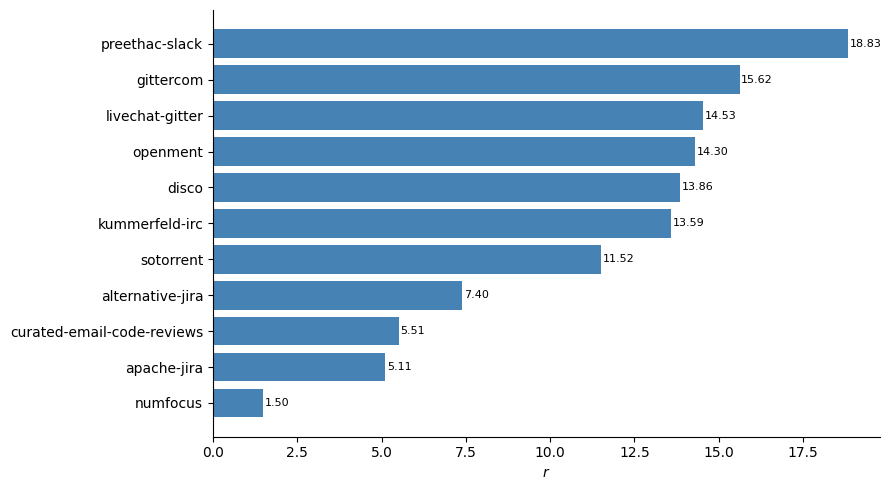

In [8]:
# Sub-RQ 1 · layer-mix as a second, coarser signature, and the per-platform
# affordance table. Platform label is read from the corpus registry, not re-derived.
prof = profiles.reset_index(drop=True)
layer_cols = [c for c in prof.columns if c.startswith("layer_")]
prof["platform"] = prof.corpus.map(lambda cid: CORPUS_REGISTRY.get(cid, ("?", "?", "?"))[1])
layer_df = prof[["corpus", "tokens", "genre","rate_per_1k_tokens"] + layer_cols].copy().sort_values("rate_per_1k_tokens")
for c in layer_cols:
    layer_df[c] = (1000 * layer_df[c] / layer_df["tokens"]).round(2)  # per-1k-token layer rates
print("Sub-RQ 1 · platform affordance table (per 1k tokens):")
display(layer_df.round(4))

# Publication figure: token rate + unit prevalence by platform.
import matplotlib.pyplot as plt
plot_df = prof.sort_values("rate_per_1k_tokens")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_df.corpus, plot_df.rate_per_1k_tokens, color="steelblue")
for i, v in enumerate(plot_df.rate_per_1k_tokens):
    ax.text(v + 0.05, i, f"{v:.2f}", va="center", fontsize=8)
ax.set_xlabel(r"$r$")
#ax.set_title("Sub-RQ 1 · Non-knowledge density by corpus/platform")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
#fig.savefig("notebooks/figs/fig_subrq1_platform_affordances.pdf")
plt.show()

In [10]:
# Sub-RQ 2 · project (:Venue) level NK aggregates + live governance/domain labels.
# Built once; Sub-RQ 3 reuses `ven` (venue-level signal rows).
ven = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND {NK_SIGNAL_PREDICATE}
RETURN coalesce(p.corpus_id,'') AS corpus,
       coalesce(p.venue_id,'') AS venue_id,
       s.layer AS layer, s.subcategory AS subcategory,
       count(s) AS signals, count(DISTINCT u) AS nk_units
""", non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)

ven_den = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u)
RETURN coalesce(p.corpus_id,'') AS corpus,
       coalesce(p.venue_id,'') AS venue_id,
       count(DISTINCT u) AS units, sum(coalesce(u.token_count,0)) AS tokens
""")

ven = ven.merge(ven_den, on=["corpus", "venue_id"], how="left")

ven["genre"] = ven.corpus.map(genre_of)

ven = ven[ven.genre != "EXCLUDED"]

# ven["se_native"] = ven.subcategory.isin(SE_NATIVE_LEX)


# # Live governance mapping (no schema/YAML change — analysis-side, sourced).
# GOVERNANCE_MAP = {
#     # commercial / corporate open-source instances in Alternative Jira
#     "mojang": "commercial", "redhat": "commercial", "mongodb": "commercial",
#     "qt": "commercial", "sonatype": "commercial", "spring": "commercial",
#     "mariadb": "commercial", "jfrog": "commercial", "inteldaos": "commercial",
#     # meritocratic foundation
#     "apache": "foundation",
# }
# def _alt_instance(vid: str):
#     parts = vid.split(":")
#     return parts[2] if len(parts) >= 4 else None   # jira:alternative-jira:<instance>:<project>

# def assign_governance(corpus, vid):
#     if corpus == "apache-jira":
#         return "foundation"
#     if corpus == "alternative-jira":
#         return GOVERNANCE_MAP.get(_alt_instance(vid), "other")
#     return "other"

# def assign_domain(corpus):
#     return {"curated-email-code-reviews": "systems", "kummerfeld-irc": "systems",
#             "numfocus": "scientific", "gittercom": "web", "livechat-gitter": "web"}\
#            .get(corpus, "other")

# ven["governance"] = [assign_governance(c, v) for c, v in zip(ven.corpus, ven.venue_id)]
# ven["domain"] = ven.corpus.map(assign_domain)

# Venue-level profile (density + SE-native share), min-unit filter to avoid noise. #, "governance", "domain"
ven_prof = ven.groupby(["corpus", "venue_id"]).agg(
    signals=("signals", "sum"), nk_units=("nk_units", "sum"),
    units=("units", "first"), tokens=("tokens", "first")).reset_index()
ven_prof["rate_per_1k_tokens"] = 1000 * ven_prof.signals / ven_prof.tokens.replace(0, np.nan)
# SE-native share per venue, computed cleanly and merged onto the profile.
# native = ven.groupby(["corpus", "venue_id"]).apply(
#     lambda d: int(d.loc[d.se_native, "signals"].sum()), include_groups=False
# ).rename("se_native_sig").reset_index()
# tot = ven.groupby(["corpus", "venue_id"]).signals.sum().rename("tot_sig").reset_index()
#share = native.merge(tot, on=["corpus", "venue_id"])
# share["se_native_share"] = share.se_native_sig / share.tot_sig.replace(0, np.nan)
#   
#ven_prof = tot.copy()
MIN_UNITS = 500
ven_prof = ven_prof[ven_prof.units >= MIN_UNITS].copy()
print(f"Sub-RQ 2 · venue-level profiles (>= {MIN_UNITS} units):")
# display(ven_prof[ven_prof.governance != "other"].groupby("governance")["rate_per_1k_tokens"].agg(
#     ["count", "mean", "median"]).round(4))
# display(ven_prof.groupby("governance")["rate_per_1k_tokens"].agg(
#     ["count", "mean", "median"]).round(4))
ven_prof.head()


Sub-RQ 2 · venue-level profiles (>= 500 units):


,corpus,venue_id,signals,nk_units,units,tokens,rate_per_1k_tokens
1,alternative-jira,jira:alternative-jira:apache:aardvark,16836,8447,18364,6238608,2.698679
2,alternative-jira,jira:alternative-jira:apache:abdera,404,338,1235,42823,9.434183
3,alternative-jira,jira:alternative-jira:apache:accumulo,20065,16278,32355,1679641,11.946005
4,alternative-jira,jira:alternative-jira:apache:ace,876,760,2724,95623,9.160976
6,alternative-jira,jira:alternative-jira:apache:activemq,16195,13276,38869,2639309,6.136076


In [11]:
display(ven_prof.groupby("venue_id")["rate_per_1k_tokens"].agg(["count", "mean", "median"]).round(4))

,count,mean,median
venue_id,,,
discord:disco:Clojurians/clojure,1,15.4717,15.4717
discord:disco:Discord Gophers/golang,1,15.1452,15.1452
discord:disco:Python/python-general,1,13.5686,13.5686
discord:disco:Racket/general,1,19.0253,19.0253
gitter:gittercom:BVLC,1,12.2022,12.2022
...,...,...,...
slack:preethac-slack:clojurians/clojure,1,19.8236,19.8236
slack:preethac-slack:elmlang/beginners,1,19.2447,19.2447
slack:preethac-slack:elmlang/general,1,19.7803,19.7803


In [12]:
# Sub-RQ 2a · Project (community / Jira instance) level NK density across corpora.
import re
from itertools import combinations
# import numpy as np
# import pandas as pd
from scipy import stats
# import statsmodels.api as sm
# import statsmodels.formula.api as smf

RNG = np.random.default_rng(42)
MIN_UNITS = 500

# Optional: merge communities that are the same project under different names (document it!).
PROJECT_ALIASES = {
    # "pythondev": "python",
}

def split_venue(corpus, vid):
    """venue_id -> (project, channel)."""
    parts = vid.split(":")
    if parts[0] == "jira":
        if len(parts) >= 4:                      # jira:<corpus>:<instance>:<jira-project>
            return parts[2], parts[3]
        if len(parts) == 3:                      # jira:apache-jira:<jira-project>  (verify!)
            return "apache", parts[2]
    elif parts[1] == "livechat-gitter":
        live_parts = parts[2].split("_")
        return live_parts[0], live_parts[1]
    rest = ":".join(parts[2:])
    if "/" in rest:                              # discord/slack/gitter: <workspace>/<channel>
        return tuple(rest.split("/", 1))
    if rest:                                     # single-room venue, e.g. gitter:gittercom:BVLC
        return rest, None
    return corpus, None                        # corpus-wide venue, e.g. stackoverflow:sotorrent

# Venue profile (all venues; size filters are applied per analysis level below).
vp = (ven.groupby(["corpus", "genre", "venue_id"], as_index=False)
         .agg(signals=("signals", "sum"), units=("units", "first"), tokens=("tokens", "first")))
pc = [split_venue(c, v) for c, v in zip(vp.corpus, vp.venue_id)]
vp["project"] = pd.Series([p.lower() for p, _ in pc], index=vp.index).replace(PROJECT_ALIASES)
vp["channel"] = [c for _, c in pc]
vp["workspace"] = vp.corpus + "|" + vp.project
vp["rate_per_1k_tokens"] = 1000 * vp.signals / vp.tokens.replace(0, np.nan)

vp = vp[~vp['corpus'].isin(["openment", "numfocus", "sotorrent"])].copy()

# Parser sanity check: two examples per corpus.
display(vp.groupby("corpus").head(2)[["corpus", "venue_id", "project", "channel"]])

def boot_ci(g, n_boot=2000, alpha=0.05):
    """Venue-cluster bootstrap CI of the pooled rate (NaN if < 3 venues)."""
    if len(g) < 3:
        return np.nan, np.nan
    s, t = g.signals.to_numpy(float), g.tokens.to_numpy(float)
    idx = RNG.integers(0, len(g), size=(n_boot, len(g)))
    b = 1000 * s[idx].sum(1) / t[idx].sum(1)
    return tuple(np.quantile(b, [alpha / 2, 1 - alpha / 2]))

def summarise(df, keys):
    rows = []
    for k, g in df.groupby(keys):
        k = k if isinstance(k, tuple) else (k,)
        lo, hi = boot_ci(g)
        r = g.rate_per_1k_tokens
        rows.append({**dict(zip(keys, k)),
                     "n_venues": len(g), "units": g.units.sum(), "tokens": g.tokens.sum(),
                     "signals": g.signals.sum(),
                     "ignorance_rate": 1000 * g.signals.sum() / g.tokens.sum(),
                     "ci_lo": lo, "ci_hi": hi,
                     "venue_median": r.median(),
                     "venue_iqr": r.quantile(.75) - r.quantile(.25)})
    return pd.DataFrame(rows)

# Project × corpus, and project overall.
proj_corpus = summarise(vp, ["project", "corpus", "genre"])
proj_corpus = proj_corpus[proj_corpus.units >= MIN_UNITS]

proj = summarise(vp, ["project"]).merge(
    vp.groupby("project").agg(n_corpora=("corpus", "nunique"),
                              corpora=("corpus", lambda s: ", ".join(sorted(s.unique()))))
      .reset_index(), on="project")
proj = proj[proj.units >= MIN_UNITS].sort_values("ignorance_rate", ascending=False)

print(f"Sub-RQ 2a · project-level NK density (pooled Σsignals/Σtokens; projects ≥ {MIN_UNITS} units)")
display(proj.round(3))

print("Distribution of project rates per genre:")
display(proj_corpus.groupby("genre").ignorance_rate.describe().round(2))

cross = proj_corpus[proj_corpus.project.isin(proj.loc[proj.n_corpora >= 2, "project"])]
if len(cross):
    print("Projects observed in ≥ 2 corpora — pooled rate per corpus:")
    display(cross.pivot_table(index="project", columns="corpus", values="ignorance_rate").round(2))

# Does the project explain NK density beyond the corpus? (quasi-Poisson, offset log tokens;
# workspace is nested in corpus, so the models are nested.)
# g = vp[vp.tokens > 0]
# off = np.log(g.tokens)
# m0 = smf.glm("signals ~ C(corpus)", g, family=sm.families.Poisson(), offset=off).fit()
# m1 = smf.glm("signals ~ C(workspace)", g, family=sm.families.Poisson(), offset=off).fit()
# d_df = m0.df_resid - m1.df_resid
# if m1.df_resid > 0 and d_df > 0:
#     phi = m1.pearson_chi2 / m1.df_resid
#     F = (m0.deviance - m1.deviance) / d_df / phi
#     print(f"Project effect beyond corpus: F({d_df:.0f}, {m1.df_resid:.0f}) = {F:.2f}, "
#           f"p = {stats.f.sf(F, d_df, m1.df_resid):.2g}; dispersion φ = {phi:.1f}; "
#           f"share of corpus-residual deviance explained = {(m0.deviance - m1.deviance) / m0.deviance:.1%}")

,corpus,venue_id,project,channel
0,alternative-jira,jira:alternative-jira:apache:aapche-age-2,apache,aapche-age-2
1,alternative-jira,jira:alternative-jira:apache:aardvark,apache,aardvark
1236,apache-jira,jira:apache-jira:aar,apache,aar
1237,apache-jira,jira:apache-jira:abdera,apache,abdera
1871,curated-email-code-reviews,mailing_list:curated-email-code-reviews:ffmpeg,ffmpeg,NaN
1872,curated-email-code-reviews,mailing_list:curated-email-code-reviews:kernel,kernel,NaN
1874,disco,discord:disco:Clojurians/clojure,clojurians,clojure
1875,disco,discord:disco:Discord Gophers/golang,discord gophers,golang
1878,gittercom,gitter:gittercom:BVLC,bvlc,NaN
1879,gittercom,gitter:gittercom:Boris-Em,boris-em,NaN


Sub-RQ 2a · project-level NK density (pooled Σsignals/Σtokens; projects ≥ 500 units)


,project,n_venues,units,tokens,signals,ignorance_rate,ci_lo,ci_hi,venue_median,venue_iqr,n_corpora,corpora
29,data-8,1,534,8822,257,29.132,NaN,NaN,29.132,0.000,1,gittercom
86,lightbend,1,1739,32534,725,22.284,NaN,NaN,22.284,0.000,1,gittercom
40,eslint,1,40622,576860,12226,21.194,NaN,NaN,21.194,0.000,1,gittercom
87,macdownapp,1,1067,22069,463,20.980,NaN,NaN,20.980,0.000,1,gittercom
149,stylelint,1,1051,12149,244,20.084,NaN,NaN,20.084,0.000,1,gittercom
21,ceylon,1,116995,1173631,23421,19.956,NaN,NaN,19.956,0.000,1,gittercom
2,akkadev,1,53805,539468,10655,19.751,NaN,NaN,19.751,0.000,1,gittercom
22,clojurians,2,37286,603838,11878,19.671,NaN,NaN,17.648,2.176,2,"disco, preethac-slack"
84,less,1,715,11751,230,19.573,NaN,NaN,19.573,0.000,1,gittercom
139,scikit-learn,1,9715,138462,2699,19.493,NaN,NaN,19.493,0.000,1,gittercom


Distribution of project rates per genre:


,count,mean,std,min,25%,50%,75%,max
genre,,,,,,,,
chat,138.0,15.25,3.72,0.07,13.50,15.68,17.53,29.13
email,3.0,5.03,1.21,3.68,4.54,5.40,5.70,6.01
tracker,17.0,7.50,2.10,3.73,6.66,7.63,9.36,10.89


Projects observed in ≥ 2 corpora — pooled rate per corpus:


corpus,alternative-jira,apache-jira,disco,gittercom,livechat-gitter,preethac-slack
project,,,,,,
angular,NaN,NaN,NaN,13.71,14.60,NaN
apache,6.95,5.11,NaN,15.63,NaN,NaN
appium,NaN,NaN,NaN,8.15,8.50,NaN
clojurians,NaN,NaN,15.47,NaN,NaN,19.82
ethereum,NaN,NaN,NaN,14.01,11.19,NaN


In [13]:
# Sub-RQ 2b · Channel profile of the TOP_K projects with the highest pooled NK density.
TOP_K = 5
REQUIRE_MULTI_CHANNEL = True    # single-room projects have nothing to decompose
MIN_UNITS_CHANNEL = MIN_UNITS

n_ch = vp[vp.units >= MIN_UNITS_CHANNEL].groupby("project").size()
cand = proj.copy()
if REQUIRE_MULTI_CHANNEL:
    cand = cand[cand.project.map(n_ch).fillna(0) >= 2]
top_projects = cand.nlargest(TOP_K, "ignorance_rate").project.tolist()
print("Top projects:", top_projects)

ch = vp[vp.project.isin(top_projects) & (vp.units >= MIN_UNITS_CHANNEL)].copy()
ch["project_rate"] = ch.project.map(proj.set_index("project").ignorance_rate)
ch["rate_ratio_vs_project"] = ch.rate_per_1k_tokens / ch.project_rate
ch["token_share_in_project"] = ch.tokens / ch.groupby("project").tokens.transform("sum")
ch = ch.sort_values(["project", "rate_per_1k_tokens"], ascending=[True, False])
display(ch[["project", "corpus", "channel", "units", "tokens", "signals",
            "rate_per_1k_tokens", "rate_ratio_vs_project", "token_share_in_project"]].round(3))

# Within-project heterogeneity.
def wcv(d):
    """Token-weighted coefficient of variation of channel rates."""
    w, r = d.tokens, d.rate_per_1k_tokens
    m = np.average(r, weights=w)
    return np.sqrt(np.average((r - m) ** 2, weights=w)) / m

spread = ch.groupby("project").apply(lambda d: pd.Series({
    "n_channels": len(d),
    "min_rate": d.rate_per_1k_tokens.min(), "max_rate": d.rate_per_1k_tokens.max(),
    "max_min_ratio": d.rate_per_1k_tokens.max() / d.rate_per_1k_tokens.min(),
    "weighted_cv": wcv(d)}), include_groups=False)
print("Within-project heterogeneity including Token-weighted coefficient of variation of channel rates")
display(spread.round(3))

# Per-layer density per channel (signals per 1k tokens, so channels stay comparable).
ven_pc = ven.merge(vp[["corpus", "venue_id", "project", "channel", "workspace"]],
                   on=["corpus", "venue_id"])
lay = (ven_pc[ven_pc.venue_id.isin(ch.venue_id)]
       .groupby(["project", "corpus", "channel", "layer"]).signals.sum()
       .unstack("layer", fill_value=0))
lay_rate = 1000 * lay.div(ch.set_index(["project", "corpus", "channel"]).tokens, axis=0)
display(lay_rate.round(2))

Top projects: ['clojurians', 'elmlang', 'angular', 'ethereum', 'sakai']


,project,corpus,channel,units,tokens,signals,rate_per_1k_tokens,rate_ratio_vs_project,token_share_in_project
2021,angular,livechat-gitter,angular,835937,9837555,143595,14.597,1.005,0.919
1909,angular,gittercom,NaN,66771,868114,11905,13.714,0.944,0.081
4188,clojurians,preethac-slack,clojure,35754,582638,11550,19.824,1.008,0.965
1874,clojurians,disco,clojure,1532,21200,328,15.472,0.787,0.035
4190,elmlang,preethac-slack,general,39060,670971,13272,19.780,1.018,0.352
4189,elmlang,preethac-slack,beginners,81470,1235148,23770,19.245,0.990,0.648
1933,ethereum,gittercom,NaN,14167,217691,3050,14.011,1.193,0.197
2025,ethereum,livechat-gitter,welcome,74324,890146,9958,11.187,0.953,0.803
1139,sakai,alternative-jira,contrib,881,27411,343,12.513,1.149,0.003
1113,sakai,alternative-jira,contrib,7447,342133,3838,11.218,1.030,0.032


Within-project heterogeneity including Token-weighted coefficient of variation of channel rates


,n_channels,min_rate,max_rate,max_min_ratio,weighted_cv
project,,,,,
angular,2.0,13.714,14.597,1.064,0.017
clojurians,2.0,15.472,19.824,1.281,0.041
elmlang,2.0,19.245,19.780,1.028,0.013
ethereum,2.0,11.187,14.011,1.252,0.096
sakai,16.0,5.325,12.513,2.350,0.047


layer                                                           lexical  \
project    corpus           channel                                       
angular    gittercom        nan                                     NaN   
           livechat-gitter  angular                                0.40   
clojurians disco            clojure                                0.47   
           preethac-slack   clojure                                0.37   
elmlang    preethac-slack   beginners                              0.34   
                            general                                0.34   
ethereum   gittercom        nan                                     NaN   
           livechat-gitter  welcome                                0.37   
sakai      alternative-jira contrib                                9.63   
                            contrib                                0.77   
                            contrib                               14.49   
                            contrib                                0.66   
                            contrib                                7.88   
                            contrib                               12.21   
                            contrib                               16.49   
                            contrib                                8.43   
                            contrib                               10.82   
                            contrib                                3.95   
                            contrib                               13.62   
                            contrib                                7.17   
                            contrib                               16.36   
                            dashboard                              0.18   
                            sakai                                  0.24   
                            sakai-production-pilot-deployments     0.17   

layer                                                           morpho_syntactic  \
project    corpus           channel                                                
angular    gittercom        nan                                              NaN   
           livechat-gitter  angular                                        13.24   
clojurians disco            clojure                                        13.87   
           preethac-slack   clojure                                        18.16   
elmlang    preethac-slack   beginners                                      17.24   
                            general                                        17.96   
ethereum   gittercom        nan                                              NaN   
           livechat-gitter  welcome                                        10.45   
sakai      alternative-jira contrib                                       353.95   
                            contrib                                        28.36   
                            contrib                                       532.49   
                            contrib                                        24.40   
                            contrib                                       289.61   
                            contrib                                       448.75   
                            contrib                                       606.00   
                            contrib                                       309.65   
                            contrib                                       397.82   
                            contrib                                       145.01   
                            contrib                                       500.41   
                            contrib                                       263.52   
                            contrib                                       601.15   
                            dashboard                                       9.63   
                            sakai

In [14]:
# Sub-RQ 2c · Recurring channel types across projects and corpora.
MIN_PROJECTS = 2          # a channel type must recur in ≥ this many workspaces
CHANNEL_GROUPS = {        # optional merges after canonicalisation — a coding decision, report it
    # "beginners": "help", "questions": "help",
}

def canonical_channel(project, channel):
    if isinstance(channel, float):
        return CHANNEL_GROUPS.get(None, None)
    c = channel.lower().strip()
    c = re.sub(rf"^{re.escape(project)}[-_ ]+", "", c)    # python-general -> general
    return CHANNEL_GROUPS.get(c, c)

vc = vp[vp.units >= MIN_UNITS_CHANNEL].copy()
vc["ctype"] = [canonical_channel(p, c) for p, c in zip(vc.project, vc.channel)]
freq = (vc.groupby("ctype").agg(n_workspaces=("workspace", "nunique"),
                                n_corpora=("corpus", "nunique"))
          .sort_values("n_workspaces", ascending=False))
display(freq.head(10))
types = freq.index[freq.n_workspaces >= MIN_PROJECTS].tolist()
# types = ["help", "general"]   # or fix explicitly
print("Recurring channel types:", types)
rc = vc[vc.ctype.isin(types)].copy()

# (a) Channel type × corpus (pooled, with venue-bootstrap CIs).
by_type_corpus = summarise(rc, ["ctype", "corpus"])
display(by_type_corpus.pivot_table(index="ctype", columns="corpus", values="ignorance_rate").round(2))
display(by_type_corpus.round(3))

# (b) Channel type × workspace (pooled per cell).
ws = rc.groupby(["workspace", "corpus", "ctype"], as_index=False)[["signals", "tokens"]].sum()
ws["rate"] = 1000 * ws.signals / ws.tokens
wide = ws.pivot_table(index=["workspace", "corpus"], columns="ctype", values="rate")
display(wide.round(2))

# (c) Paired within-workspace comparison for every pair of types.
rows = []
for a, b in combinations(types, 2):
    pair = wide[[a, b]].dropna()
    if len(pair) == 0:
        continue
    ratio = pair[a] / pair[b]
    rows.append({"a": a, "b": b, "n_paired": len(pair),
                 "n_a_higher": int((pair[a] > pair[b]).sum()),
                 "median_ratio_a/b": ratio.median(),
                 "geo_mean_ratio_a/b": np.exp(np.log(ratio).mean()),
                 #"wilcoxon_p": stats.wilcoxon(pair[a], pair[b]).pvalue if len(pair) >= 2 else np.nan
                 })
display(pd.DataFrame(rows).round(4))

# (d) Quasi-Poisson with workspace fixed effects: rate ratios of channel types,
#     pooled and per corpus.
# def ctype_rate_ratios(d, label):
#     d = d[d.tokens > 0]
#     if len(d) <= d.workspace.nunique() + d.ctype.nunique() - 1 or d.ctype.nunique() < 2:
#         print(f"[{label}] not enough within-workspace contrast — skipped"); return
#     m = smf.glm("signals ~ C(ctype) + C(workspace)", d, family=sm.families.Poisson(),
#                 offset=np.log(d.tokens)).fit(scale="X2")
#     ci = m.conf_int()
#     out = pd.DataFrame({"rate_ratio": np.exp(m.params), "lo": np.exp(ci[0]),
#                         "hi": np.exp(ci[1]), "p": m.pvalues}).filter(like="C(ctype)", axis=0)
#     print(f"[{label}] reference type = {sorted(d.ctype.unique())[0]}")
#     display(out.round(3))

# ctype_rate_ratios(ws, "all corpora")
# for c, d in ws.groupby("corpus"):
#     ctype_rate_ratios(d, c)

# (e) Per-layer density by channel type × corpus.
lay3 = (ven_pc.merge(rc[["venue_id", "ctype"]], on="venue_id")
              .groupby(["ctype", "corpus", "layer"]).signals.sum()
              .unstack("layer", fill_value=0))
tok3 = rc.groupby(["ctype", "corpus"]).tokens.sum()
display((1000 * lay3.div(tok3, axis=0)).round(2))

,n_workspaces,n_corpora
ctype,,
general,3,2
pig,2,2
datalab,2,2
ddlutils,2,2
rave,2,2
deltaspike,2,2
derby,2,2
ratis,2,2
rat,2,2


Recurring channel types: ['general', 'pig', 'datalab', 'ddlutils', 'rave', 'deltaspike', 'derby', 'ratis', 'rat', 'rampart', 'qpid', 'polygene', 'drill', 'pluto', 'plc4x', 'pivot', 'edgent', 'ftpserver', 'phoenix', 'pdfbox', 'parquet', 'etch', 'orc', 'falcon', 'felix', 'fineract', 'flagon', 'flex', 'flink', 'flume', 'fop', 'forge', 'reef', 'zookeeper', 'rocketmq', 'daffodil', 'synapse', 'celix', 'clerezza', 'submarine', 'clojure', 'streams', 'streampipes', 'stratos', 'storm', 'cocoon', 'spot', 'spark', 'solr', 'sling', 'slider', 'singa', 'shiro', 'shindig', 'shell', 'shale', 'continuum', 'santuario', 'couchdb', 'samza', 's2graph', 'rya', 'ctakes', 'curator', 'cxf', 'river', 'gearpump', 'systemds', 'impala', 'nifi', 'netbeans', 'nemo', 'myriad', 'inlong', 'iotdb', 'ivy', 'ivyde', 'mxnet', 'muse', 'mnemonic', 'jclouds', 'jdo', 'jena', 'johnzon', 'mesos', 'jspwiki', 'juddi', 'kafka', 'karaf', 'knox', 'kudu', 'kylin', 'libcloud', 'livy', 'log4net', 'lucy', 'madlib', 'mahout', 'incubator', 

corpus,alternative-jira,apache-jira,disco,preethac-slack
ctype,,,,
abdera,9.43,7.62,NaN,NaN
accumulo,11.95,8.96,NaN,NaN
ace,9.16,5.89,NaN,NaN
airavata,2.34,4.35,NaN,NaN
ambari,4.08,3.23,NaN,NaN
any23,7.53,6.12,NaN,NaN
aries,8.98,5.79,NaN,NaN
arrow,7.37,6.71,NaN,NaN
asterixdb,4.96,2.83,NaN,NaN


,ctype,corpus,n_venues,units,tokens,signals,ignorance_rate,ci_lo,ci_hi,venue_median,venue_iqr
0,abdera,alternative-jira,1,1235,42823,404,9.434,NaN,NaN,9.434,0.0
1,abdera,apache-jira,1,603,23743,181,7.623,NaN,NaN,7.623,0.0
2,accumulo,alternative-jira,1,32355,1679641,20065,11.946,NaN,NaN,11.946,0.0
3,accumulo,apache-jira,1,9332,384547,3446,8.961,NaN,NaN,8.961,0.0
4,ace,alternative-jira,1,2724,95623,876,9.161,NaN,NaN,9.161,0.0
...,...,...,...,...,...,...,...,...,...,...,...
376,yunikorn,apache-jira,1,5571,187756,749,3.989,NaN,NaN,3.989,0.0
377,zeppelin,alternative-jira,1,39266,2279816,12250,5.373,NaN,NaN,5.373,0.0
378,zeppelin,apache-jira,1,11446,517509,2255,4.357,NaN,NaN,4.357,0.0
379,zookeeper,alternative-jira,1,45123,2940598,31622,10.754,NaN,NaN,10.754,0.0


,ctype,abdera,accumulo,ace,airavata,ambari,any23,aries,arrow,asterixdb,atlas,...,wink,wookie,xalanc,xap,xbean,xmlbeans,yetus,yunikorn,zeppelin,zookeeper
workspace,corpus,,,,,,,,,,,,,,,,,,,,,
alternative-jira|apache,alternative-jira,9.43,11.95,9.16,2.34,4.08,7.53,8.98,7.37,4.96,6.05,...,11.60,11.45,8.24,6.59,9.00,9.05,5.88,9.11,5.37,10.75
alternative-jira|jiraecosystem,alternative-jira,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alternative-jira|mojang,alternative-jira,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alternative-jira|mongodb,alternative-jira,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alternative-jira|redhat,alternative-jira,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
alternative-jira|spring,alternative-jira,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
apache-jira|apache,apache-jira,7.62,8.96,5.89,4.35,3.23,6.12,5.79,6.71,2.83,2.95,...,7.85,7.52,5.30,4.23,7.07,6.57,9.40,3.99,4.36,6.49
disco|clojurians,disco,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
disco|python,disco,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,a,b,n_paired,n_a_higher,median_ratio_a/b,geo_mean_ratio_a/b
0,pig,datalab,2,2,2.4505,2.2400
1,pig,ddlutils,2,1,1.0689,1.0399
2,pig,rave,2,1,1.0094,0.9986
3,pig,deltaspike,2,1,0.8825,0.8680
4,pig,derby,2,0,0.6983,0.6976
...,...,...,...,...,...,...
17387,accumulo,unomi,2,2,1.8061,1.7979
17388,accumulo,cassandra,2,1,1.2240,1.1920
17389,tamaya,unomi,2,1,1.0783,1.0416
17390,tamaya,cassandra,2,1,0.7468,0.6906


layer                       lexical  morpho_syntactic  rhetorical
ctype     corpus                                                 
abdera    alternative-jira     0.40              8.66        0.37
          apache-jira          0.51              6.78        0.34
accumulo  alternative-jira     0.25             11.16        0.53
          apache-jira          0.31              8.18        0.47
ace       alternative-jira     0.19              8.71        0.26
...                             ...               ...         ...
yunikorn  apache-jira          0.16              3.67        0.15
zeppelin  alternative-jira     0.10              5.01        0.26
          apache-jira          0.16              3.99        0.20
zookeeper alternative-jira     0.23             10.17        0.35
          apache-jira          0.44              5.82        0.22

[381 rows x 3 columns]

Sub-RQ 2 · governance contrasts (Mann-Whitney U, Holm-corrected):


,metric,contrast,n_c,n_f,U,p,p_corrected
0,rate_per_1k_tokens,commercial vs foundation · NK density,275,793,123995.0,0.0007,0.0014
1,se_native_share,commercial vs foundation · SE-native share,275,793,109037.5,1.0000,1.0000


Sub-RQ 2 · Kruskal-Wallis over domains ['systems', 'scientific', 'web']: H=151.272, p=0.0000


,count,mean,median
domain,,,
scientific,94,19.1663,19.5418
systems,8,38.5134,43.3229
web,126,44.6705,45.5300


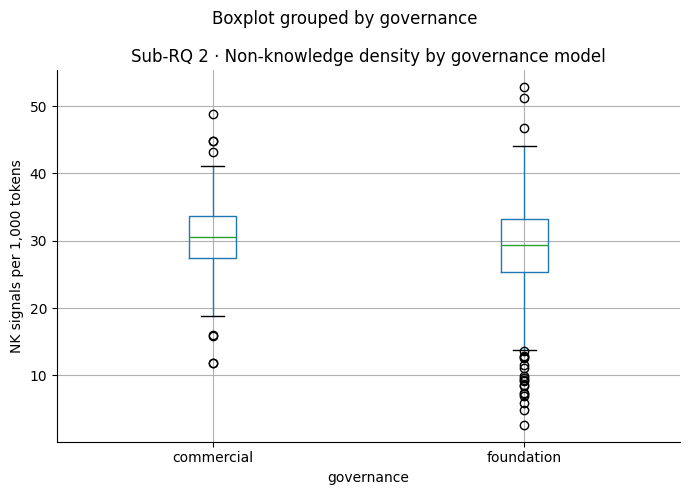

In [11]:
# Sub-RQ 2 · governance & domain contrasts (non-parametric, Holm-corrected).
from scipy import stats as sps

def _u(grp, label, metric="rate_per_1k_tokens"):
    a = ven_prof[ven_prof.governance == grp[0]][metric].dropna()
    b = ven_prof[ven_prof.governance == grp[1]][metric].dropna()
    if len(a) < 2 or len(b) < 2:
        return {"contrast": label, "n_a": len(a), "n_b": len(b), "U": np.nan, "p": np.nan}
    U, p = sps.mannwhitneyu(a, b, alternative="two-sided")
    return {"contrast": label, "n_a": len(a), "n_b": len(b), "U": U, "p": p}

gov_contrasts = pd.DataFrame([_u(("commercial", "foundation"), "commercial vs foundation"),
                              _u(("foundation", "commercial"), "foundation vs commercial")])
# Holm correction across the distinct hypothesis tests
import itertools
tests = [_u(("commercial", "foundation"), "commercial vs foundation (NK rate)"),
         _u(("commercial", "foundation"), "commercial vs foundation (SE-native share)")]
# reuse _u with metric switch:
tests2 = []
for metric, lab in [("rate_per_1k_tokens", "commercial vs foundation · NK density"),
                    ("se_native_share", "commercial vs foundation · SE-native share")]:
    a = ven_prof[(ven_prof.governance=="commercial")][metric].dropna()
    b = ven_prof[(ven_prof.governance=="foundation")][metric].dropna()
    if len(a) >= 2 and len(b) >= 2:
        U, p = sps.mannwhitneyu(a, b, alternative="two-sided")
        tests2.append({"metric": metric, "contrast": lab, "n_c": len(a), "n_f": len(b),
                       "U": U, "p": p})
    else:
        tests2.append({"metric": metric, "contrast": lab, "n_c": len(a), "n_f": len(b),
                       "U": np.nan, "p": np.nan})
res2 = pd.DataFrame(tests2)
# Holm-Bonferroni correction (clean, vectorised)
res2 = res2.dropna(subset=["p"]).sort_values("p").reset_index(drop=True)
m = len(res2)
res2["p_corrected"] = [min(1.0, res2.loc[i, "p"] * (m - i)) for i in range(m)]
res2["p_corrected"] = np.maximum.accumulate(res2.p_corrected)
print("Sub-RQ 2 · governance contrasts (Mann-Whitney U, Holm-corrected):")
display(res2.round(4))

# Domain contrast (3+ groups -> Kruskal-Wallis) on NK density.
dom = [g for g in ["systems", "scientific", "web"] if g in set(ven_prof.domain)]
if len(dom) >= 2:
    groups = [ven_prof[ven_prof.domain == d].rate_per_1k_tokens.dropna() for d in dom]
    H, p_kw = sps.kruskal(*groups)
    print(f"Sub-RQ 2 · Kruskal-Wallis over domains {dom}: H={H:.3f}, p={p_kw:.4f}")
    display(ven_prof[ven_prof.domain.isin(dom)].groupby("domain")["rate_per_1k_tokens"].agg(
        ["count", "mean", "median"]).round(4))
else:
    print("Sub-RQ 2 · domain contrast skipped (need ≥2 domains with data).")

# Boxplot of governance NK density.
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 5))
ven_prof[ven_prof.governance != "other"].boxplot(column="rate_per_1k_tokens", by="governance", ax=ax)
ax.set_ylabel("NK signals per 1,000 tokens"); ax.set_title("")
ax.set_title("Sub-RQ 2 · Non-knowledge density by governance model")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); 
#fig.savefig("notebooks/figs/fig_subrq2_project_governance.pdf")
plt.show()


In [12]:
# Sub-RQ 3 · Arm A — cross-platform community-of-practice pair (Clojure).
# Macro community-of-practice samples (same language/domain/community label), NOT
# tracked individuals (identity resolution is out of scope — FRAMEWORK_DESIGN §4.8).
CLA_SLACK = "slack:preethac-slack:clojurians/clojure"
CLA_DISC  = "discord:disco:Clojurians/clojure"
PY_SLACK  = "slack:preethac-slack:pythondev/help"

def venue_signature(vid):
    v = ven[ven.venue_id == vid]
    if v.empty:
        return None
    sig_v = v.groupby("subcategory").signals.sum()
    toks = v.tokens.iloc[0] or 0
    out = sig_v.to_dict()
    out["tokens"] = toks
    return out

def cos_venue(a_id, b_id):
    A, B = venue_signature(a_id), venue_signature(b_id)
    if A is None or B is None:
        return np.nan
    ta, tb = A.get("tokens", 0) or 0, B.get("tokens", 0) or 0
    if not ta or not tb:
        return np.nan
    keys = (set(A) | set(B)) - {"tokens"}
    va = np.array([A.get(k, 0.0) / ta for k in keys])
    vb = np.array([B.get(k, 0.0) / tb for k in keys])
    denom = np.linalg.norm(va) * np.linalg.norm(vb)
    return 1.0 - (va @ vb) / denom if denom else 1.0

same_comm = cos_venue(CLA_SLACK, CLA_DISC)      # same community, different platform
diff_comm = cos_venue(CLA_SLACK, PY_SLACK)      # different community, same platform
print(f"Sub-RQ 3 Arm A · Clojure(Slack) vs Clojure(Discord) cos-dist = {same_comm:.4f}")
print(f"Sub-RQ 3 Arm A · Clojure(Slack) vs Python(Slack)  cos-dist = {diff_comm:.4f}")
print("→ Community-epistemic persistence if same-community distance < cross-community "

      "distance (shared platform).")
print("NOTE: 1 defensible pair ⇒ descriptive, effect-size only, NO p-values.")


Sub-RQ 3 Arm A · Clojure(Slack) vs Clojure(Discord) cos-dist = 0.0039
Sub-RQ 3 Arm A · Clojure(Slack) vs Python(Slack)  cos-dist = 0.0058
→ Community-epistemic persistence if same-community distance < cross-community distance (shared platform).
NOTE: 1 defensible pair ⇒ descriptive, effect-size only, NO p-values.


In [13]:
# Sub-RQ 3 · Arm B — cross-dataset project replication (live set-intersection).
# 229 Apache project keys appear in BOTH apache-jira (MSR'23) and alternative-jira
# (instance 'apache', MSR'22). Live filter in Pandas; no schema change.
def _project_of(vid):
    parts = vid.split(":")
    if parts[1] == "apache-jira":
        return parts[-1]
    if parts[1] == "alternative-jira" and len(parts) >= 4:
        return parts[-1]
    return None

jira_ven = ven[ven.corpus.isin(["apache-jira", "alternative-jira"])].copy()
jira_ven["project"] = jira_ven.venue_id.map(_project_of)
jira_ven["instance"] = jira_ven.venue_id.map(_alt_instance)
jira_ven = jira_ven.dropna(subset=["project"])

# artefact volume per project per corpus (for the ≥threshold filter)
vol = ven_den[ven_den.corpus.isin(["apache-jira", "alternative-jira"])].copy()
vol["project"] = vol.venue_id.map(_project_of)
vol["instance"] = vol.venue_id.map(_alt_instance)
vol = vol.dropna(subset=["project"])

apache23 = set(vol[(vol.corpus == "apache-jira")].project)
apache22 = set(vol[(vol.corpus == "alternative-jira") & (vol["instance"] == "apache")].project)
shared = apache23 & apache22

MIN_VOL = 5000
shared_top = [p for p in shared
              if (vol[(vol.corpus=="apache-jira") & (vol.project==p)].units.sum() or 0) >= MIN_VOL
              and (vol[(vol.corpus=="alternative-jira") & (vol["instance"]=="apache") & (vol.project==p)].units.sum() or 0) >= MIN_VOL]
print(f"Sub-RQ 3 Arm B · {len(shared)} shared Apache projects; {len(shared_top)} with ≥{MIN_VOL} units in BOTH.")

# Compare per-project, per-dataset NK density on the shared set.
rows = []
for proj in shared_top:
    for corpus in ["apache-jira", "alternative-jira"]:
        sel = jira_ven[(jira_ven.project == proj) & (jira_ven.corpus == corpus)]
        t = sel.tokens.iloc[0] if len(sel) else 0
        s = sel.signals.sum()
        rows.append({"project": proj, "dataset": corpus,
                     "rate_per_1k_tokens": 1000 * s / t if t else np.nan,
                     "signals": int(s), "tokens": int(t)})
rep = pd.DataFrame(rows)
print("\nSub-RQ 3 Arm B · shared-project NK density by dataset (top 15):")
display(rep.sort_values("rate_per_1k_tokens", ascending=False).head(15))
# Stability: correlation of per-project density across the two datasets.
wide = rep.pivot(index="project", columns="dataset", values="rate_per_1k_tokens").dropna()
if len(wide) >= 3:
    rho, pcorr = sps.spearmanr(wide["apache-jira"], wide["alternative-jira"])
    print(f"\nSpearman ρ (per-project density, MSR'23 vs MSR'22) = {rho:.3f} (n={len(wide)})")
    print("→ High ρ indicates measurement/extraction stability across datasets.")


Sub-RQ 3 Arm B · 229 shared Apache projects; 58 with ≥5000 units in BOTH.

Sub-RQ 3 Arm B · shared-project NK density by dataset (top 15):


,project,dataset,rate_per_1k_tokens,signals,tokens
81,daffodil,alternative-jira,41.788513,23207,555344
80,daffodil,apache-jira,40.968773,11002,268546
5,uima,alternative-jira,39.794217,32859,825723
3,felix,alternative-jira,38.433629,54554,1419434
57,derby,alternative-jira,37.892134,211650,5585592
4,uima,apache-jira,36.927283,14667,397186
105,solr,alternative-jira,36.887030,337797,9157609
39,calcite,alternative-jira,36.778408,62428,1697409
91,cassandra,alternative-jira,36.771928,334263,9090168
23,sling,alternative-jira,36.444789,75929,2083398



Spearman ρ (per-project density, MSR'23 vs MSR'22) = 0.656 (n=58)
→ High ρ indicates measurement/extraction stability across datasets.


### Sub-RQ 2 · Role asymmetry (facet of project governance)
*Two independent role contrasts across two genres (a role effect replicated across
genres is not an artefact of the medium). This is one facet of Sub-RQ 2, alongside
the governance and domain contrasts above.*

> Deep-dive on the OpenMent mentor/mentee gap (data-hygiene checks, project- and
> author-level decomposition, thread-level qualitative sampling): see
> `notebooks/03_rq3b_openment.ipynb`.

In [14]:
# RQ3b — Setting 1: OpenMent mentor vs mentee.
# Roles are the dataset's own annotation (project_roles.csv), carried into the
# ingested doc metadata by the ingester (CHANGELOG 2026-08-14). The notebook
# reads them from the source CSV as the durable, version-controlled source of
# truth; project_id is recovered from the parent artefact's repo ('openment:<pid>').
OMENT_CSV = Path(settings.datasets_root) / "OpenMent-dataset" / "project_roles.csv"
roles = {}
if OMENT_CSV.exists():
    for row in pd.read_csv(OMENT_CSV).itertuples():
        pid, uid, role = row.project_id, row.user_id, row.role
        roles[(pid, uid)] = role
    print(f"Loaded {len(roles)} (project, user) → role mappings")
else:
    print("⚠️ OpenMent project_roles.csv not found — RQ3b setting 1 skipped.")

om_units = q("""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') = 'openment'
RETURN u.id AS tu_id, coalesce(u.author_login, '') AS author,
       coalesce(p.repo, '') AS repo, u.token_count AS tokens
""")
if len(om_units) and OMENT_CSV.exists():
    om_units["project_id"] = om_units.repo.map(lambda r: r.split(":", 1)[1] if ":" in r else "")
    om_units["role"] = [roles.get((pid, a), None)
                        for pid, a in zip(om_units.project_id, om_units.author)]
    lab = om_units[om_units.role.isin(["mentor", "mentee"])]
    print(f"\nOpenMent units with a known role: {len(lab):,} "
          f"(mentor={int((lab.role=='mentor').sum()):,}, "
          f"mentee={int((lab.role=='mentee').sum()):,})")
    # NK rate by role (join signals)
    om_sig = q(f"""
    MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
    MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
    WHERE @sandbox(u) AND coalesce(p.corpus_id, '') = 'openment' AND {NK_SIGNAL_PREDICATE}
    RETURN u.id AS tu_id, count(s) AS nk_signals
    """, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)
    om = om_units.merge(om_sig, on="tu_id", how="left").fillna({"nk_signals": 0})
    om = om[om.role.isin(["mentor", "mentee"])]
    om["tokens"] = om.tokens.fillna(0).astype(int)
    per = om.groupby("role").agg(units=("tu_id", "size"), tokens=("tokens", "sum"),
                                 nk=("nk_signals", "sum"))
    per["nk_per_1k_tokens"] = 1000 * per.nk / per.tokens.replace(0, np.nan)
    display(per.round(3))
    print("\n→ A role difference here (with the same project threads) supports "
          "RQ3b's claim that NK marks the speaker's role, not just the genre.")
else:
    print("OpenMent not ingested (or roles file absent) — setting 1 skipped.")

Loaded 6422 (project, user) → role mappings

OpenMent units with a known role: 566,369 (mentor=213,738, mentee=352,631)


,units,tokens,nk,nk_per_1k_tokens
role,,,,
mentee,352631,9677476,381980.0,39.471
mentor,213738,5729562,297003.0,51.837



→ A role difference here (with the same project threads) supports RQ3b's claim that NK marks the speaker's role, not just the genre.


In [15]:
# RQ3b — Setting 2: curated review email, patch author vs reviewer.
# Distinguisher: the doc's entity_type metadata (comment → reviewer; patch /
# series / mailinglist → author). Read from the raw_emails collection in Mongo;
# joins to graph TextUnits via the parent EmailMessage urn.
from pymongo import MongoClient
try:
    mongo = MongoClient(settings.mongo_uri, serverSelectionTimeoutMS=3000)
    coll = mongo[settings.mongo_db_name]["raw_emails"]
    cursor = coll.find({"corpus_id": "curated-email-code-reviews",
                        "metadata.entity_type": {"$in": ["comment", "patch", "series", "mailinglist"]}},
                       {"urn": 1, "metadata.entity_type": 1})
    ent = pd.DataFrame(list(cursor))
    mongo.close()
except Exception as exc:
    ent = pd.DataFrame()
    print("⚠️ Mongo read failed:", exc)

if len(ent):
    ent["entity_type"] = ent.metadata.apply(
        lambda m: m.get("entity_type") if isinstance(m, dict) else None)
    ent["role"] = np.where(ent.entity_type == "comment", "reviewer", "patch_author")
    ent = ent[ent.role.notna()]
    print(f"Curated emails: {len(ent):,} with entity_type "
          f"({int((ent.role=='reviewer').sum()):,} reviewer, "
          f"{int((ent.role=='patch_author').sum()):,} author)")
    em_units = q("""
    MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:EmailMessage)
    WHERE @sandbox(u) AND coalesce(p.corpus_id, '') = 'curated-email-code-reviews'
    RETURN p.urn AS urn, u.id AS tu_id, u.token_count AS tokens
    """)
    em = em_units.merge(ent[["urn", "role"]], on="urn", how="inner")
    em_sig = q(f"""
    MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:EmailMessage)
    MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
    WHERE @sandbox(u) AND coalesce(p.corpus_id, '') = 'curated-email-code-reviews'
      AND {NK_SIGNAL_PREDICATE}
    RETURN u.id AS tu_id, count(s) AS nk_signals
    """, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)
    em = em.merge(em_sig, on="tu_id", how="left").fillna({"nk_signals": 0})
    em["tokens"] = em.tokens.fillna(0).astype(int)
    per = em.groupby("role").agg(units=("tu_id", "size"), tokens=("tokens", "sum"),
                                 nk=("nk_signals", "sum"))
    per["nk_per_1k_tokens"] = 1000 * per.nk / per.tokens.replace(0, np.nan)
    display(per.round(3))
    print("\n→ Replicated role contrast: does the author/reviewer difference in")
    print("  email point the same way as the mentor/mentee difference in OpenMent?")
else:
    print("Curated email not ingested (or entity metadata unavailable) — setting 2 skipped.")

Curated emails: 10,087,431 with entity_type (4,830,328 reviewer, 5,257,103 author)


,units,tokens,nk,nk_per_1k_tokens
role,,,,
patch_author,7509178,317515675,7610086.0,23.968
reviewer,7052677,225843865,7176216.0,31.775



→ Replicated role contrast: does the author/reviewer difference in
  email point the same way as the mentor/mentee difference in OpenMent?


---
## Sub-RQ 4 · Communicative functions, referents & trajectories *(independent, qualitative)*
*Formerly the RQ4 hand-coded taxonomy section — now an independent phenomenological
study. Instrument: `CODING_MANUAL_v0.3.md` §10. The old 28-category taxonomy,
400-unit frame, multi-actor flag and predictions P1–P6 are deferred to a companion
study (`REFINED_RQS_v0.3.md` §6).*

**Question.** When a software engineer articulates non-knowledge, what **communicative
act** are they performing (Dimension 1), what **technical object** does the gap
refer to (Dimension 2), and how is it **collaboratively resolved** (Dimension 3)?

**Frame (disclosed).** The sample is **detector-positive** (every unit carries ≥1
active NK signal); it characterises how expressed NK is communicated, NOT what the
pipeline misses (blind-spot coverage is deferred).

**Reliability.** 2 independent raters × 100 units × 3 dimensions, Cohen's κ per
dimension; 5 pilot units excluded from the 100; disagreements adjudicated to consensus.

In [16]:
# Sub-RQ 4 · deterministic stratified sampling (100 units; seed 42).
# Reproducible: Cypher ORDER BY u.id (deterministic) + seeded NumPy RNG.
# Stratification: 25 units × 4 signal mechanisms (lexical / morpho-syntactic /
# rhetorical / classifier), sampled across the four genres. Chat units are drawn
# from threadable platforms (IRC, Slack) so the trajectory dimension is codable.
import os
os.makedirs("notebooks/figs", exist_ok=True)

SAMPLE_PATH = "notebooks/qualitative_sample_100.csv"
MECHANISMS = ["lexical", "morpho_syntactic", "rhetorical", "classifier"]
# chat restricted to platforms with conversation structure (REPLIES_TO / Conversation)
CHAT_PLATFORMS = ["kummerfeld-irc", "preethac-slack"]
FRAME = {}

if GRAPH_EMPTY:
    print("Sub-RQ 4 skipped — no in-scope signals (run the pipeline first).")
else:
    rng = np.random.default_rng(42)
    for mech in MECHANISMS:
        # deterministic candidate pool per mechanism
        pool = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
WHERE @sandbox(u) AND {NK_SIGNAL_PREDICATE}
  AND s.layer = $mech
  AND NOT (coalesce(p.corpus_id,'') IN $chat_excl)
RETURN coalesce(p.corpus_id,'') AS corpus,
       coalesce(p.venue_id,'') AS venue_id,
       p.record_id AS parent_id, u.id AS unit_id, u.text AS unit_text
ORDER BY u.id LIMIT 2000
""", mech=mech, non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS,
           chat_excl=CHAT_PLATFORMS)
        if len(pool):
            pool = pool.sample(frac=1.0, random_state=rng).iloc[:25]
            pool["mechanism"] = mech
            FRAME[mech] = pool
    sample = pd.concat(FRAME.values(), ignore_index=True) if FRAME else pd.DataFrame()
    sample = sample[sample.unit_text.notna()]
    if len(sample):
        # Drop to exactly 100 (and cap at 25 per mechanism defensively).
        sample = sample.groupby("mechanism").head(25).head(100).reset_index(drop=True)
        sample["genre"] = sample.corpus.map(genre_of)
        # Thread context placeholder: the sampling frame carries parent + unit text;
        # full preceding/following-turn context is exported in the coding sheet via a
        # follow-up join (enrichment `REPLIES_TO` / Conversation blocks).
        for col in ["rater1_function", "rater1_referent", "rater1_trajectory", "rater1_notes",
                    "rater2_function", "rater2_referent", "rater2_trajectory", "rater2_notes",
                    "adjudicated_function", "adjudicated_referent", "adjudicated_trajectory"]:
            sample[col] = ""
        sample.to_csv(SAMPLE_PATH, index=False)
        print(f"Sub-RQ 4 · exported {len(sample)} units to {SAMPLE_PATH}")
        display(sample.groupby(["mechanism", "genre"]).size().unstack(fill_value=0))
    else:
        print("Sub-RQ 4 · no candidate units found — sampling frame empty.")


TransientError: {neo4j_code: Neo.TransientError.General.MemoryPoolOutOfMemoryError} {message: The allocation of an extra 2.0 MiB would use more than the limit 5.6 GiB. Currently using 5.6 GiB. dbms.memory.transaction.total.max threshold reached} {gql_status: 51N72} {gql_status_description: error: system configuration or operation exception - memory pool out of memory. Failed to allocate memory in a memory pool. See dbms.memory.transaction.total.max in the neo4j.conf file.}

In [ ]:
# Sub-RQ 4 · Inter-rater reliability (2 raters, Cohen's κ per dimension).
from sklearn.metrics import cohen_kappa_score, confusion_matrix

def load_coding(path=SAMPLE_PATH):
    if not os.path.exists(path):
        return None
    return pd.read_csv(path)

dims = {"function": ("rater1_function", "rater2_function"),
        "referent": ("rater1_referent", "rater2_referent"),
        "trajectory": ("rater1_trajectory", "rater2_trajectory")}

coding = load_coding()
if coding is None or coding.empty or coding.rater1_function.isna().all():
    print("Sub-RQ 4 · no completed coding found — run the raters, save the CSV, then re-run.")
else:
    rows = []
    for dim, (r1c, r2c) in dims.items():
        a = coding[r1c].astype("str").str.strip()
        b = coding[r2c].astype("str").str.strip()
        keep = (a != "") & (b != "") & (a != "nan") & (b != "nan")
        if dim == "trajectory":
            keep &= (a != "UNCODABLE_STRUCTURE_ABSENT") & (b != "UNCODABLE_STRUCTURE_ABSENT")
        a, b = a[keep], b[keep]
        if len(a) == 0:
            rows.append({"dimension": dim, "n": 0, "kappa": np.nan, "po": np.nan})
            continue
        kappa = cohen_kappa_score(a, b)
        po = (a == b).mean()
        rows.append({"dimension": dim, "n": len(a), "kappa": kappa, "po": po})
        # disagreement diagnosis
        if len(set(a) | set(b)) <= 6:
            labs = sorted(set(a) | set(b))
            cm = confusion_matrix(a, b, labels=labs)
            print(f"\n{dim} · confusion matrix (rows=rater1, cols=rater2):")
            print(pd.DataFrame(cm, index=labs, columns=labs).fillna(0).astype(int))
    irr = pd.DataFrame(rows)
    print("\nSub-RQ 4 · inter-rater reliability (Cohen's κ, observed agreement):")
    display(irr.round(4))


In [ ]:
# Sub-RQ 4 · adjudicated typology + vignettes (after raters save consensus codes).
coding = load_coding()
if coding is None or coding.empty or coding.adjudicated_function.isna().all():
    print("Sub-RQ 4 · adjudicated codes not present yet — nothing to plot.")
else:
    for col in ["adjudicated_function", "adjudicated_referent", "adjudicated_trajectory"]:
        coding[col] = coding[col].astype("str").str.strip().replace({"": None, "nan": None})
    import matplotlib.pyplot as plt
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    titles = ["Communicative function", "Epistemic referent", "Conversational trajectory"]
    cols = ["adjudicated_function", "adjudicated_referent", "adjudicated_trajectory"]
    for ax, col, title in zip(axes, cols, titles):
        counts = coding[col].value_counts(dropna=True)
        ax.bar(counts.index, counts.values, color="steelblue")
        ax.set_title(title); ax.set_ylabel("units"); ax.tick_params(axis="x", rotation=30)
        ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout(); fig.savefig("notebooks/figs/fig_subrq4_qualitative_typology.pdf")
    plt.show()
    print("\nSub-RQ 4 · selected vignettes (unit_id · function · referent · trajectory):")
    sel = coding.dropna(subset=["adjudicated_function"]).head(5)
    for _, r in sel.iterrows():
        print(f"\n[{r.unit_id}] ({r.corpus}) {r.adjudicated_function} / {r.adjudicated_referent} / {r.adjudicated_trajectory}")
        print("  ", (str(r.unit_text)[:160].replace(chr(10), " ")))


---
## RQ5 · Marker–classifier disagreement *(Layer 4 — methodological boundary)*
*Unchanged core: the 2×2 is reported per genre, and chat-register disagreement is
interpreted as at least partly the classifier operating out-of-domain. The
independence constraint is binding: marker weights are never fitted to reduce
off-diagonal mass.*

In [ ]:
# RQ5 — Per-genre marker×classifier 2×2, on a sampled unit table.
# marker_positive := unit has >= 1 active NK non-classifier signal (the SAME
# predicate RQ2/RQ3/RQ4 use). classifier_positive := CLASSIFIED_AS label == 1.
SAMPLE_PER_CORPUS = 3000
rng = np.random.default_rng(11)

units = q(f"""
MATCH (u:TextUnit)<-[:HAS_TEXT]-(p:Artefact)
WHERE @sandbox(u) AND coalesce(p.corpus_id, '') IN $corpora
WITH u, coalesce(p.corpus_id, '') AS corpus,
     EXISTS {{ MATCH (u)-[:HAS_SIGNAL]->(s:Signal)
              WHERE {NK_SIGNAL_PREDICATE} }} AS marker_pos
OPTIONAL MATCH (u)-[:CLASSIFIED_AS]->(v:ClassifierVerdict)
WITH u.id AS tu_id, corpus, marker_pos, coalesce(v.label, -1) AS clf_label
WHERE clf_label >= 0
RETURN tu_id, corpus, marker_pos, clf_label
""", corpora=list(present.corpus), non_nk=NON_NK_SUBCATS, rule_version=V, active_rules=ACTIVE_RULE_IDS)
units["genre"] = units.corpus.map(genre_of)
units = units[units.genre != "EXCLUDED"]

rows = []
for genre, g in units.groupby("genre"):
    if not len(g):
        continue
    s = g.sample(min(len(g), SAMPLE_PER_CORPUS), random_state=rng)
    mp = int((s.marker_pos == True).sum())
    cp = int((s.clf_label == 1).sum())
    both = int(((s.marker_pos == True) & (s.clf_label == 1)).sum())
    neither = int(((s.marker_pos == False) & (s.clf_label == 0)).sum())
    rows.append({"genre": genre, "n": len(s), "marker+": mp, "clf+": cp,
                 "both": both, "neither": neither,
                 "marker+/clf−": mp - both, "marker−/clf+": cp - both})
rq5 = pd.DataFrame(rows, columns=["genre", "n", "marker+", "clf+", "both",
                                  "neither", "marker+/clf−", "marker−/clf+"])
print("RQ5 · 2×2 per genre (sampled; n per genre below):")
display(rq5)
print("\nChat-register interpretation: the marker−/clf+ cell in chat is partly")
print("out-of-domain signal (RoBERTa on IRC slang) — declare it as such, and")
print("report marker precision per rule on a labelled sample before promoting.")
print("\nIndependence constraint (binding): marker weights were never fitted to")
print("reduce these off-diagonal cells; the classifier never gates any annotator.")

In [ ]:
# RQ5 continued — per-rule marker counts per genre (precision input).
# The reliability table needs a hand-labelled sample; the graph side gives the
# per-rule counts that stratify that sample.
rule_counts = (sig.groupby(["genre", "rule_id"]).signals.sum().reset_index()
                  .sort_values("signals", ascending=False))
print("Top 20 (genre, rule) signal counts — the strata for the RQ5 precision sample:")
display(rule_counts.head(20))

---
## Scope discipline — what this paper deliberately does NOT ask

- **Temporal evolution of NK** — next (graph-ML) paper.
- **Causal effect of NK on project outcomes** — needs an outcome variable and an
  identification strategy.
- **Whether the taxonomies should be repaired** — a merged taxonomy needs validation
  on a second corpus; stating the gap, not filling it.
- **Blind-spot / marker coverage, category population, multi-actor (P1–P6)** — the
  old hand-coded taxonomy RQ4a–c and its predictions are **deferred to a companion
  study** (`REFINED_RQS_v0.3.md` §6); Sub-RQ 4's detector-positive frame does not
  measure these.
- **NK vs emotion** — the SO emotion gold labels and OpenMent sentiment columns are
  deliberately not ingested (framework conflation). Explicitly deferred.

*(End of `03_rq_analysis.ipynb`.)*